# **Effect of Attention Type and Attention Position in a Pretrained ResNet50**



---



## Import libraries

In [ ]:
!pip install -q tensorflow tensorflow-datasets scikit-learn seaborn pandas matplotlib

import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Output folders
OUTPUT_DIR = "/content/resnet50_attention_results"
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")

for directory in [OUTPUT_DIR, PLOT_DIR, MODEL_DIR, RESULT_DIR]:
    os.makedirs(directory, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Output directory:", OUTPUT_DIR)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output directory: /content/resnet50_attention_results


In [ ]:
# Plot settings
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Liberation Serif'
mpl.rcParams['font.size'] = 15
mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['axes.titleweight'] = 'bold'
mpl.rcParams['axes.titlesize'] = 15
mpl.rcParams['axes.labelsize'] = 15
mpl.rcParams['xtick.labelsize'] = 15
mpl.rcParams['ytick.labelsize'] = 15
mpl.rcParams['legend.fontsize'] = 15
mpl.rcParams['savefig.dpi'] = 600

In [ ]:
def save_plot(fig, filename):
    """
    Save a figure as a high-resolution PNG.
    """
    filepath = os.path.join(PLOT_DIR, filename)

    fig.savefig(
        filepath,
        format="png",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", filepath)


def finish_plot(ax, title, xlabel, ylabel):
    """
    Apply consistent formatting to a plot.
    """
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_ylabel(ylabel, fontweight="bold")

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.6
    )

    ax.legend(
        frameon=True,
        fontsize=11
    )

    ax.tick_params(axis="both", labelsize=12)


print("Plot settings configured.")

Plot settings configured.


In [ ]:
!pip install -q importlib_resources

# ============================================================
# DATASET CONFIGURATION
# ============================================================

IMAGE_SIZE = 224
NUM_CLASSES = 5
BATCH_SIZE = 32

CLASS_NAMES = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

# Load the complete dataset
dataset, info = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True
)

images = []
labels = []

for image, label in tfds.as_numpy(dataset):
    images.append(image)
    labels.append(label)

images = np.array(images, dtype=object)
labels = np.array(labels, dtype=np.int32)

print("Total images:", len(labels))
print("Number of classes:", len(np.unique(labels)))

print("\nClass distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        class_name,
        ":",
        int(np.sum(labels == class_id))
    )

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Total images: 3670
Number of classes: 5

Class distribution:
daisy : 898
dandelion : 633
roses : 799
sunflowers : 699
tulips : 641


In [ ]:
# ============================================================
# 70% TRAIN, 15% VALIDATION, 15% TEST
# ============================================================

indices = np.arange(len(labels))

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_indices]
)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test_indices))

print(
    "Train percentage:",
    round(100 * len(train_indices) / len(labels), 2)
)

print(
    "Validation percentage:",
    round(100 * len(val_indices) / len(labels), 2)
)

print(
    "Test percentage:",
    round(100 * len(test_indices) / len(labels), 2)
)

Training images: 2569
Validation images: 550
Testing images: 551
Train percentage: 70.0
Validation percentage: 14.99
Test percentage: 15.01


In [ ]:
# ============================================================
# IMAGE PREPROCESSING
# ============================================================

def prepare_images(indices):
    """
    Resize images to 224x224 and return float32 arrays.
    """
    output = []

    for idx in indices:
        image = images[idx]

        image = tf.image.resize(
            image,
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        image = tf.cast(image, tf.float32)

        output.append(image.numpy())

    return np.array(output, dtype=np.float32)


X_train_raw = prepare_images(train_indices)
X_val_raw = prepare_images(val_indices)
X_test_raw = prepare_images(test_indices)

y_train = labels[train_indices]
y_val = labels[val_indices]
y_test = labels[test_indices]

# Preprocess using the ImageNet ResNet50 convention
X_train = preprocess_input(X_train_raw.copy())
X_val = preprocess_input(X_val_raw.copy())
X_test = preprocess_input(X_test_raw.copy())

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (2569, 224, 224, 3)
X_val: (550, 224, 224, 3)
X_test: (551, 224, 224, 3)


Saved: /content/resnet50_attention_results/plots/sample_images.png


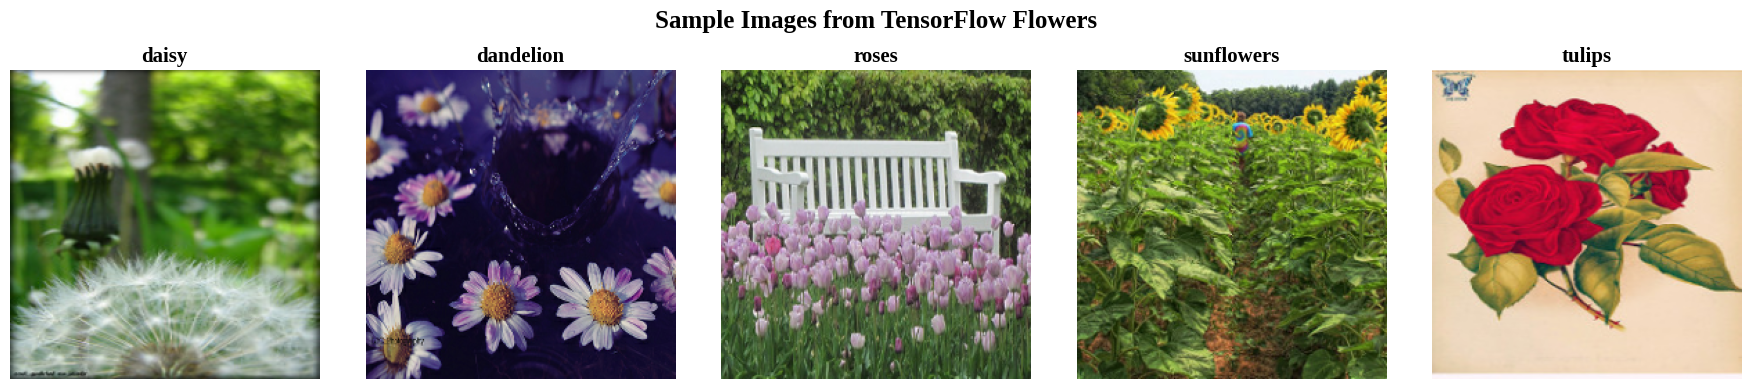

In [ ]:
# ============================================================
# SAMPLE IMAGES
# ============================================================

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 4))

for class_id, ax in enumerate(axes):

    sample_indices = np.where(y_train == class_id)[0]

    sample_id = sample_indices[0]

    ax.imshow(
        np.clip(
            X_train_raw[sample_id] / 255.0,
            0,
            1
        )
    )

    ax.set_title(
        CLASS_NAMES[class_id],
        fontweight="bold"
    )

    ax.axis("off")

fig.suptitle(
    "Sample Images from TensorFlow Flowers",
    fontweight="bold"
)

fig.tight_layout()

save_plot(fig, "sample_images.png")

plt.show()

In [ ]:
# ============================================================
# CHANNEL ATTENTION
# ============================================================

def channel_attention(x, reduction=16, name="channel_attention"):

    channels = int(x.shape[-1])

    hidden_channels = max(channels // reduction, 1)

    # Global average pooling
    avg_pool = layers.GlobalAveragePooling2D(
        keepdims=True,
        name=f"{name}_gap"
    )(x)

    # Shared MLP
    dense1 = layers.Dense(
        hidden_channels,
        activation="relu",
        name=f"{name}_fc1"
    )

    dense2 = layers.Dense(
        channels,
        activation="sigmoid",
        name=f"{name}_fc2"
    )

    weights = dense2(dense1(avg_pool))

    # Apply channel weights
    output = layers.Multiply(
        name=f"{name}_multiply"
    )([x, weights])

    return output

In [ ]:
# ============================================================
# SPATIAL ATTENTION
# ============================================================

def spatial_attention(
    x,
    kernel_size=7,
    name="spatial_attention"
):

    # Average across channels
    avg_map = layers.Lambda(
        lambda t: tf.reduce_mean(
            t,
            axis=-1,
            keepdims=True
        ),
        name=f"{name}_avg"
    )(x)

    # Maximum across channels
    max_map = layers.Lambda(
        lambda t: tf.reduce_max(
            t,
            axis=-1,
            keepdims=True
        ),
        name=f"{name}_max"
    )(x)

    # Concatenate the two maps
    combined = layers.Concatenate(
        axis=-1,
        name=f"{name}_concat"
    )([avg_map, max_map])

    # Generate the spatial attention map
    attention_map = layers.Conv2D(
        filters=1,
        kernel_size=kernel_size,
        padding="same",
        activation="sigmoid",
        name=f"{name}_conv"
    )(combined)

    # Refine the input feature map
    output = layers.Multiply(
        name=f"{name}_multiply"
    )([x, attention_map])

    return output

In [ ]:
# ============================================================
# CHANNEL -> SPATIAL ATTENTION
# ============================================================

def channel_spatial_attention(
    x,
    reduction=16,
    kernel_size=7,
    name="channel_spatial"
):

    x = channel_attention(
        x,
        reduction=reduction,
        name=f"{name}_channel"
    )

    x = spatial_attention(
        x,
        kernel_size=kernel_size,
        name=f"{name}_spatial"
    )

    return x

In [ ]:
# ============================================================
# SPATIAL -> CHANNEL ATTENTION
# ============================================================

def spatial_channel_attention(
    x,
    reduction=16,
    kernel_size=7,
    name="spatial_channel"
):

    x = spatial_attention(
        x,
        kernel_size=kernel_size,
        name=f"{name}_spatial"
    )

    x = channel_attention(
        x,
        reduction=reduction,
        name=f"{name}_channel"
    )

    return x

In [ ]:
# ============================================================
# LIGHTWEIGHT SELF-ATTENTION (ROBUST TO FUNCTIONAL API TRACING)
# ============================================================

class SelfAttention2D(layers.Layer):

    def __init__(self, reduction=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction = reduction

    def build(self, input_shape):
        self.channels = int(input_shape[-1])
        self.hidden_channels = max(self.channels // self.reduction, 1)

        self.query_conv = layers.Conv2D(
            self.hidden_channels,
            kernel_size=1,
            padding="same"
        )

        self.key_conv = layers.Conv2D(
            self.hidden_channels,
            kernel_size=1,
            padding="same"
        )

        self.value_conv = layers.Conv2D(
            self.hidden_channels,
            kernel_size=1,
            padding="same"
        )

        self.output_conv = layers.Conv2D(
            self.channels,
            kernel_size=1,
            padding="same"
        )

        self.gamma = self.add_weight(
            name="gamma",
            shape=(),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, x):
        # Safely extract dynamic dimensions for reshaping
        dynamic_shape = tf.shape(x)
        batch_size = dynamic_shape[0]
        height = dynamic_shape[1]
        width = dynamic_shape[2]

        # Query, key, value projections
        q = self.query_conv(x)
        k = self.key_conv(x)
        v = self.value_conv(x)

        # Reshape to (batch_size, height * width, channels) safely
        q_flat = tf.reshape(q, [batch_size, -1, self.hidden_channels])
        k_flat = tf.reshape(k, [batch_size, -1, self.hidden_channels])
        v_flat = tf.reshape(v, [batch_size, -1, self.hidden_channels])

        # Scaled dot-product attention
        scale = tf.math.rsqrt(tf.cast(self.hidden_channels, tf.float32))
        attention = tf.matmul(q_flat, k_flat, transpose_b=True) * scale
        attention = tf.nn.softmax(attention, axis=-1)

        # Store the attention matrix if required for visualization
        self.last_attention = attention

        # Apply attention weights to values
        output = tf.matmul(attention, v_flat)

        # Reshape back to 4D tensor using the dynamic height and width
        output = tf.reshape(output, [batch_size, height, width, self.hidden_channels])

        # Final output projection
        output = self.output_conv(output)

        # Residual connection
        return x + self.gamma * output

    def compute_output_shape(self, input_shape):
        return input_shape

In [ ]:
# ============================================================
# SE ATTENTION
# ============================================================

def se_attention(x, reduction=16, name="se"):

    channels = int(x.shape[-1])

    hidden = max(channels // reduction, 1)

    weights = layers.GlobalAveragePooling2D(
        keepdims=True,
        name=f"{name}_gap"
    )(x)

    weights = layers.Dense(
        hidden,
        activation="relu",
        name=f"{name}_fc1"
    )(weights)

    weights = layers.Dense(
        channels,
        activation="sigmoid",
        name=f"{name}_fc2"
    )(weights)

    return layers.Multiply(
        name=f"{name}_multiply"
    )([x, weights])

In [ ]:
# ============================================================
# ECA ATTENTION
# ============================================================

def eca_attention(x, kernel_size=3, name="eca"):

    channels = int(x.shape[-1])

    descriptor = layers.GlobalAveragePooling2D(
        name=f"{name}_gap"
    )(x)

    descriptor = layers.Reshape(
        (channels, 1),
        name=f"{name}_reshape1"
    )(descriptor)

    descriptor = layers.Conv1D(
        filters=1,
        kernel_size=kernel_size,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1d"
    )(descriptor)

    weights = layers.Activation(
        "sigmoid",
        name=f"{name}_sigmoid"
    )(descriptor)

    weights = layers.Reshape(
        (1, 1, channels),
        name=f"{name}_reshape2"
    )(weights)

    return layers.Multiply(
        name=f"{name}_multiply"
    )([x, weights])

In [ ]:
# ============================================================
# CBAM
# ============================================================

def cbam_attention(
    x,
    reduction=16,
    kernel_size=7,
    name="cbam"
):

    x = channel_attention(
        x,
        reduction=reduction,
        name=f"{name}_channel"
    )

    x = spatial_attention(
        x,
        kernel_size=kernel_size,
        name=f"{name}_spatial"
    )

    return x

In [ ]:
# ============================================================
# COORDINATE ATTENTION
# ============================================================

def coordinate_attention(x, reduction=16, name="coordinate"):

    channels = int(x.shape[-1])

    hidden = max(channels // reduction, 8)

    # Pool separately along width and height
    pool_h = layers.Lambda(
        lambda t: tf.reduce_mean(
            t,
            axis=2,
            keepdims=True
        ),
        name=f"{name}_pool_h"
    )(x)

    pool_w = layers.Lambda(
        lambda t: tf.reduce_mean(
            t,
            axis=1,
            keepdims=True
        ),
        name=f"{name}_pool_w"
    )(x)

    # Transpose width descriptor
    pool_w = layers.Permute(
        (2, 1, 3),
        name=f"{name}_permute"
    )(pool_w)

    # Combine descriptors
    combined = layers.Concatenate(
        axis=1,
        name=f"{name}_concat"
    )([pool_h, pool_w])

    combined = layers.Conv2D(
        hidden,
        kernel_size=1,
        padding="same",
        activation="relu",
        name=f"{name}_conv1"
    )(combined)

    # Split using the dynamic height
    height = tf.shape(x)[1]
    width = tf.shape(x)[2]

    split_h = layers.Lambda(
        lambda t: t[:, :height, :, :],
        name=f"{name}_split_h"
    )(combined)

    split_w = layers.Lambda(
        lambda t: t[:, height:, :, :],
        name=f"{name}_split_w"
    )(combined)

    split_w = layers.Permute(
        (2, 1, 3),
        name=f"{name}_permute_back"
    )(split_w)

    # Produce coordinate attention maps
    att_h = layers.Conv2D(
        channels,
        kernel_size=1,
        activation="sigmoid",
        padding="same",
        name=f"{name}_att_h"
    )(split_h)

    att_w = layers.Conv2D(
        channels,
        kernel_size=1,
        activation="sigmoid",
        padding="same",
        name=f"{name}_att_w"
    )(split_w)

    return layers.Multiply(
        name=f"{name}_multiply"
    )([x, att_h, att_w])

In [ ]:
# ============================================================
# RESNET50 STAGES
# ============================================================

POSITIONS = {
    "P1": "conv2_block3_out",
    "P2": "conv3_block4_out",
    "P3": "conv4_block6_out",
    "P4": "conv5_block3_out"
}

# Principal positions used in the laboratory
MAIN_POSITIONS = ["P2", "P3", "P4"]

# Additional position for extended experiments
ALL_POSITIONS = ["P1", "P2", "P3", "P4"]

ATTENTION_TYPES = [
    "none",
    "channel",
    "spatial",
    "channel_spatial",
    "self",
    "se",
    "eca",
    "cbam",
    "coordinate"
]

print("Attention positions:", POSITIONS)
print("Attention types:", ATTENTION_TYPES)

Attention positions: {'P1': 'conv2_block3_out', 'P2': 'conv3_block4_out', 'P3': 'conv4_block6_out', 'P4': 'conv5_block3_out'}
Attention types: ['none', 'channel', 'spatial', 'channel_spatial', 'self', 'se', 'eca', 'cbam', 'coordinate']


In [ ]:
# ============================================================
# MODEL BUILDER
# ============================================================

def build_resnet_attention_model(
    attention_type="none",
    position="P3",
    kernel_size=7,
    attention_order="channel_spatial",
    multi_positions=None,
    dropout_rate=0.3,
    augmentation=True
):
    """
    Build ResNet50 with an optional attention module.

    Parameters
    ----------
    attention_type:
        none, channel, spatial, channel_spatial,
        self, se, eca, cbam, coordinate

    position:
        P1, P2, P3, or P4

    kernel_size:
        Spatial attention convolution kernel.

    attention_order:
        channel_spatial or spatial_channel.

    multi_positions:
        Optional list such as ["P3", "P4"].
    """

    inputs = layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        name="input_image"
    )

    x = inputs

    # Augmentation is applied only during training.
    if augmentation:

        x = layers.RandomFlip(
            "horizontal",
            seed=SEED,
            name="random_flip"
        )(x)

        x = layers.RandomRotation(
            0.05,
            seed=SEED,
            name="random_rotation"
        )(x)

        x = layers.RandomZoom(
            0.10,
            seed=SEED,
            name="random_zoom"
        )(x)

    # Load ImageNet-pretrained ResNet50.
    backbone = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    # Initially freeze the backbone.
    backbone.trainable = False

    # Obtain the feature tensors for the selected stages.
    feature_outputs = {
        pos: backbone.get_layer(layer_name).output
        for pos, layer_name in POSITIONS.items()
    }

    # Select positions for single-stage or multi-stage attention.
    if multi_positions is not None:
        selected_positions = list(multi_positions)

    elif attention_type == "none":
        selected_positions = []

    else:
        selected_positions = [position]

    if any(pos not in POSITIONS for pos in selected_positions):
        raise ValueError(
            f"Invalid attention position: {selected_positions}"
        )

    # Construct the backbone path with attention.
    if not selected_positions:

        # Baseline: ordinary ResNet50.
        x = backbone(x)

    else:

        # Apply the backbone until the earliest selected stage.
        stage_indices = {
            "P1": 1,
            "P2": 2,
            "P3": 3,
            "P4": 4
        }

        first_position = min(
            selected_positions,
            key=lambda p: stage_indices[p]
        )

        first_stage = feature_outputs[first_position]

        prefix = Model(
            inputs=backbone.input,
            outputs=first_stage,
            name="resnet50_prefix"
        )

        x = prefix(x)

        # Continue through each selected stage and its attention.
        for idx, pos in enumerate(
            sorted(selected_positions, key=lambda p: stage_indices[p])
        ):

            if idx > 0:

                # Resume from the preceding stage output.
                previous_pos = sorted(
                    selected_positions,
                    key=lambda p: stage_indices[p]
                )[idx - 1]

                previous_stage = feature_outputs[previous_pos]

                tail = Model(
                    inputs=previous_stage,
                    outputs=feature_outputs[pos],
                    name=f"resnet50_{previous_pos}_to_{pos}"
                )

                x = tail(x)

            # Insert attention at the current position.
            if attention_type == "none":
                pass

            elif attention_type == "channel":

                x = channel_attention(
                    x,
                    name=f"{pos}_channel"
                )

            elif attention_type == "spatial":

                x = spatial_attention(
                    x,
                    kernel_size=kernel_size,
                    name=f"{pos}_spatial"
                )

            elif attention_type == "channel_spatial":

                if attention_order == "channel_spatial":

                    x = channel_spatial_attention(
                        x,
                        kernel_size=kernel_size,
                        name=f"{pos}_cs"
                    )

                elif attention_order == "spatial_channel":

                    x = spatial_channel_attention(
                        x,
                        kernel_size=kernel_size,
                        name=f"{pos}_sc"
                    )

                else:
                    raise ValueError("Invalid attention order.")

            elif attention_type == "self":

                x = SelfAttention2D(
                    reduction=8,
                    name=f"{pos}_self_attention"
                )(x)

            elif attention_type == "se":

                x = se_attention(
                    x,
                    name=f"{pos}_se"
                )

            elif attention_type == "eca":

                x = eca_attention(
                    x,
                    name=f"{pos}_eca"
                )

            elif attention_type == "cbam":

                x = cbam_attention(
                    x,
                    kernel_size=kernel_size,
                    name=f"{pos}_cbam"
                )

            elif attention_type == "coordinate":

                x = coordinate_attention(
                    x,
                    name=f"{pos}_coordinate"
                )

            else:
                raise ValueError(
                    f"Unknown attention type: {attention_type}"
                )

        # Continue from the final selected position to conv5.
        last_position = max(
            selected_positions,
            key=lambda p: stage_indices[p]
        )

        if last_position != "P4":

            tail = Model(
                inputs=feature_outputs[last_position],
                outputs=backbone.output,
                name=f"resnet50_{last_position}_to_output"
            )

            x = tail(x)

    # Classification head.
    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dropout(
        dropout_rate,
        name="classifier_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="flower_predictions"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name=f"resnet50_{attention_type}_{position}"
    )

    return model

In [ ]:
# ============================================================
# BASELINE MODEL
# ============================================================

baseline_model = build_resnet_attention_model(
    attention_type="none",
    augmentation=True
)

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "resnet50_none_P3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower_predictions (Dense)      │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# ============================================================
# MODEL SHAPE TEST
# ============================================================

sample_batch = X_train[:2]

predictions = baseline_model(
    sample_batch,
    training=False
)

print("Input shape:", sample_batch.shape)
print("Output shape:", predictions.shape)

assert predictions.shape == (2, NUM_CLASSES)

print("Baseline forward pass successful.")

Input shape: (2, 224, 224, 3)
Output shape: (2, 5)
Baseline forward pass successful.


In [ ]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 3

HEAD_LR = 1e-3
FINETUNE_LR = 1e-5

# Set to False to perform only head training.
RUN_FINE_TUNING = True

# For a quick initial test, set HEAD_EPOCHS = 2
# and FINETUNE_EPOCHS = 1.

In [ ]:
# ============================================================
# REUSABLE TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    experiment_name,
    head_epochs=HEAD_EPOCHS,
    finetune_epochs=FINETUNE_EPOCHS,
    fine_tune=True
):

    print("\nTraining:", experiment_name)

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

    # Stage 1: train the new head and attention layers.
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=HEAD_LR
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_head = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=head_epochs,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    history_data = {
        key: list(value)
        for key, value in history_head.history.items()
    }

    # Stage 2: fine-tune the final backbone stage.
    if fine_tune and finetune_epochs > 0:

        print("Fine-tuning final ResNet50 stage...")

        for layer in model.layers:
            if isinstance(layer, tf.keras.Model):
                for sublayer in layer.layers:
                    if sublayer.name.startswith("conv5_"):
                        sublayer.trainable = True

                    # Keep Batch Normalization frozen.
                    if isinstance(
                        sublayer,
                        layers.BatchNormalization
                    ):
                        sublayer.trainable = False

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=FINETUNE_LR
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        history_fine = model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=finetune_epochs,
            batch_size=BATCH_SIZE,
            callbacks=callbacks,
            verbose=1
        )

        for key, value in history_fine.history.items():
            history_data.setdefault(key, []).extend(value)

    # Save training history.
    history_df = pd.DataFrame(history_data)

    history_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"{experiment_name}_history.csv"
        ),
        index=False
    )

    # Save trained model.
    model.save(
        os.path.join(
            MODEL_DIR,
            f"{experiment_name}.keras"
        )
    )

    return model, history_data

In [ ]:
# ============================================================
# TRAIN BASELINE
# ============================================================

baseline_model, baseline_history = train_model(
    baseline_model,
    experiment_name="baseline",
    fine_tune=RUN_FINE_TUNING
)


Training: baseline
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 218ms/step - accuracy: 0.6870 - loss: 0.8442 - val_accuracy: 0.8818 - val_loss: 0.3484 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 180ms/step - accuracy: 0.8614 - loss: 0.3985 - val_accuracy: 0.9036 - val_loss: 0.2976 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 184ms/step - accuracy: 0.8762 - loss: 0.3421 - val_accuracy: 0.9127 - val_loss: 0.2578 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 184ms/step - accuracy: 0.9015 - loss: 0.2640 - val_accuracy: 0.9182 - val_loss: 0.2524 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 200ms/step - accuracy: 0.9085 - loss: 0.2537 - val_accuracy: 0.9145 - val_loss: 0.2460 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.


In [ ]:
# ============================================================
# ACCURACY CURVE
# ============================================================

def plot_accuracy_history(history, filename, expt="Model"):

    fig, ax = plt.subplots(figsize=(9, 6))

    epochs = range(1, len(history["accuracy"]) + 1)

    ax.plot(
        epochs,
        history["accuracy"],
        marker="o",
        linewidth=2,
        label="Training Accuracy"
    )

    ax.plot(
        epochs,
        history["val_accuracy"],
        marker="s",
        linewidth=2,
        label="Validation Accuracy"
    )

    finish_plot(
        ax,
        f"{expt} - Training and Validation Accuracy",
        "Epoch",
        "Accuracy"
    )

    fig.tight_layout()

    save_plot(fig, filename)

    plt.show()

In [ ]:
# ============================================================
# LOSS CURVE
# ============================================================

def plot_loss_history(history, filename, expt):

    fig, ax = plt.subplots(figsize=(9, 6))

    epochs = range(1, len(history["loss"]) + 1)

    ax.plot(
        epochs,
        history["loss"],
        marker="o",
        linewidth=2,
        label="Training Loss"
    )

    ax.plot(
        epochs,
        history["val_loss"],
        marker="s",
        linewidth=2,
        label="Validation Loss"
    )

    finish_plot(
        ax,
        f"{expt} - Training and Validation Loss",
        "Epoch",
        "Cross-Entropy Loss"
    )

    fig.tight_layout()

    save_plot(fig, filename)

    plt.show()



Saved: /content/resnet50_attention_results/plots/baseline_accuracy.png


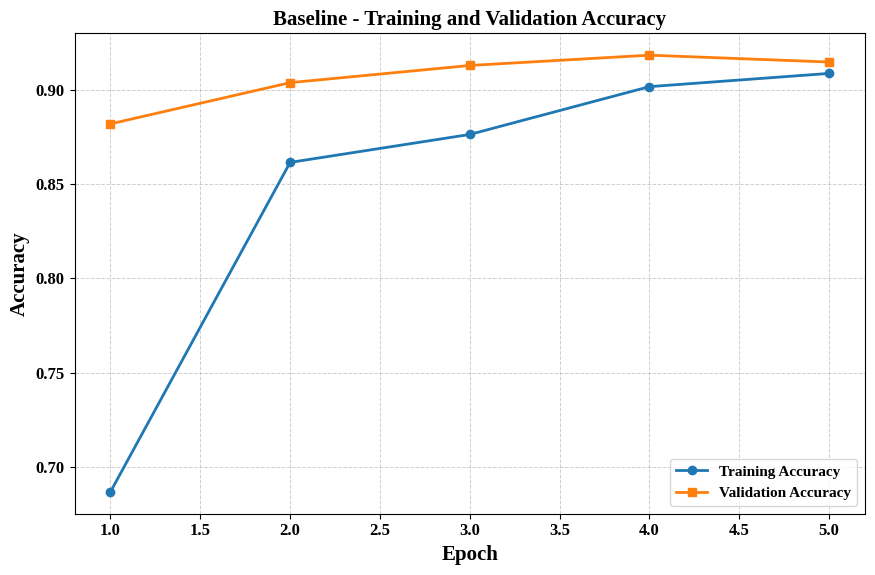

Saved: /content/resnet50_attention_results/plots/baseline_loss.png


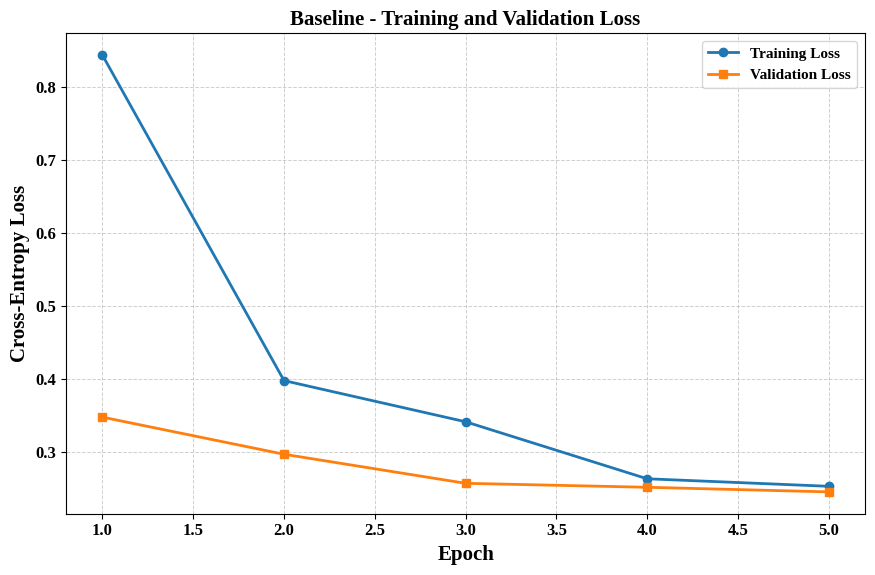

In [ ]:
# Generate baseline plots

plot_accuracy_history(
    baseline_history,
    "baseline_accuracy.png",
    "Baseline"
)

plot_loss_history(
    baseline_history,
    "baseline_loss.png",
    "Baseline"
)

In [ ]:
# ============================================================
# MODEL EVALUATION
# ============================================================

def evaluate_model(model, experiment_name):

    # Predictions
    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    # Classification metrics
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Parameter counts
    total_params = model.count_params()

    trainable_params = sum(
        np.prod(v.shape)
        for v in model.trainable_weights
    )

    # Inference timing
    timing_batch = X_test[:min(BATCH_SIZE, len(X_test))]

    # Warm-up
    for _ in range(5):
        model(timing_batch, training=False)

    if tf.config.list_physical_devices("GPU"):
        tf.test.experimental.sync_devices()

    repetitions = 30

    start_time = time.perf_counter()

    for _ in range(repetitions):
        model(timing_batch, training=False)

    if tf.config.list_physical_devices("GPU"):
        tf.test.experimental.sync_devices()

    elapsed = time.perf_counter() - start_time

    average_batch_time = elapsed / repetitions

    average_image_time_ms = (
        average_batch_time
        / len(timing_batch)
        * 1000
    )

    # Class-wise report
    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        os.path.join(
            RESULT_DIR,
            f"{experiment_name}_classification_report.csv"
        )
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    result = {
        "Model": experiment_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro_F1": macro_f1,
        "Trainable_Parameters": int(trainable_params),
        "Total_Parameters": int(total_params),
        "Inference_ms_per_image": average_image_time_ms
    }

    print("\nExperiment:", experiment_name)

    for key, value in result.items():
        print(f"{key}: {value}")

    return result, cm, y_pred, probabilities

In [ ]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

def plot_confusion_matrix(cm, title, filename):

    fig, ax = plt.subplots(figsize=(8, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Purples",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(
        title,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Predicted Class",
        fontweight="bold"
    )

    ax.set_ylabel(
        "True Class",
        fontweight="bold"
    )

    ax.grid(False)

    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)

    fig.tight_layout()

    save_plot(fig, filename)

    plt.show()


Experiment: baseline
Model: baseline
Accuracy: 0.911070780399274
Precision: 0.909537589093097
Recall: 0.9119646338067391
Macro_F1: 0.9097039878435563
Trainable_Parameters: 10245
Total_Parameters: 23597957
Inference_ms_per_image: 8.634829646875156
Saved: /content/resnet50_attention_results/plots/04_baseline_confusion_matrix.png


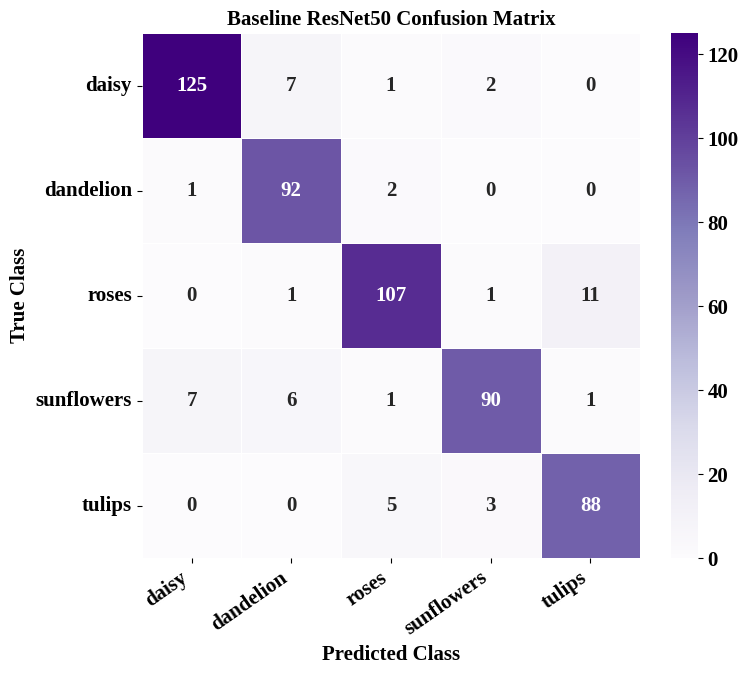

In [ ]:
# ============================================================
# BASELINE EVALUATION
# ============================================================

baseline_result, baseline_cm, baseline_pred, baseline_prob = (
    evaluate_model(
        baseline_model,
        "baseline"
    )
)

results = [baseline_result]

plot_confusion_matrix(
    baseline_cm,
    "Baseline ResNet50 Confusion Matrix",
    "04_baseline_confusion_matrix.png"
)

In [ ]:
# ============================================================
# EXPERIMENT RUNNER
# ============================================================

def run_experiment(
    experiment_name,
    attention_type,
    position="P3",
    kernel_size=7,
    attention_order="channel_spatial",
    multi_positions=None
):

    model = build_resnet_attention_model(
        attention_type=attention_type,
        position=position,
        kernel_size=kernel_size,
        attention_order=attention_order,
        multi_positions=multi_positions,
        augmentation=True
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=HEAD_LR
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model, history = train_model(
        model,
        experiment_name=experiment_name,
        fine_tune=RUN_FINE_TUNING
    )

    plot_accuracy_history(
        history,
        f"{experiment_name}_accuracy.png",
        expt=experiment_name
    )

    plot_loss_history(
        history,
        f"{experiment_name}_loss.png",
        expt=experiment_name
    )

    result, cm, y_pred, probabilities = evaluate_model(
        model,
        experiment_name
    )

    plot_confusion_matrix(
        cm,
        f"{experiment_name} Confusion Matrix",
        f"{experiment_name}_confusion_matrix.png"
    )

    return {
        "model": model,
        "history": history,
        "result": result,
        "cm": cm,
        "predictions": y_pred,
        "probabilities": probabilities
    }



Training: exp1_attention_channel
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 243ms/step - accuracy: 0.7046 - loss: 0.7612 - val_accuracy: 0.8691 - val_loss: 0.3498 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 206ms/step - accuracy: 0.8704 - loss: 0.3584 - val_accuracy: 0.8891 - val_loss: 0.3458 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.8918 - loss: 0.2948 - val_accuracy: 0.8964 - val_loss: 0.3118 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.9140 - loss: 0.2404 - val_accuracy: 0.9055 - val_loss: 0.2923 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.9245 - loss: 0.2072 - val_accuracy: 0.9000 - val_loss: 0.2975 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 266ms/step - accuracy: 0.9342 - loss: 0.1903 - val_accuracy: 0.9073 - 

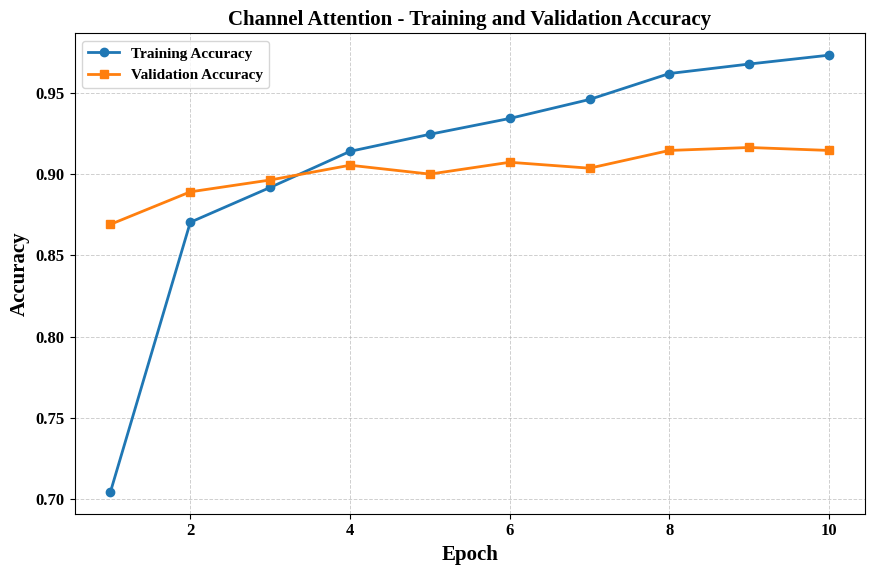

Saved: /content/resnet50_attention_results/plots/exp1_attention_channel_loss.png


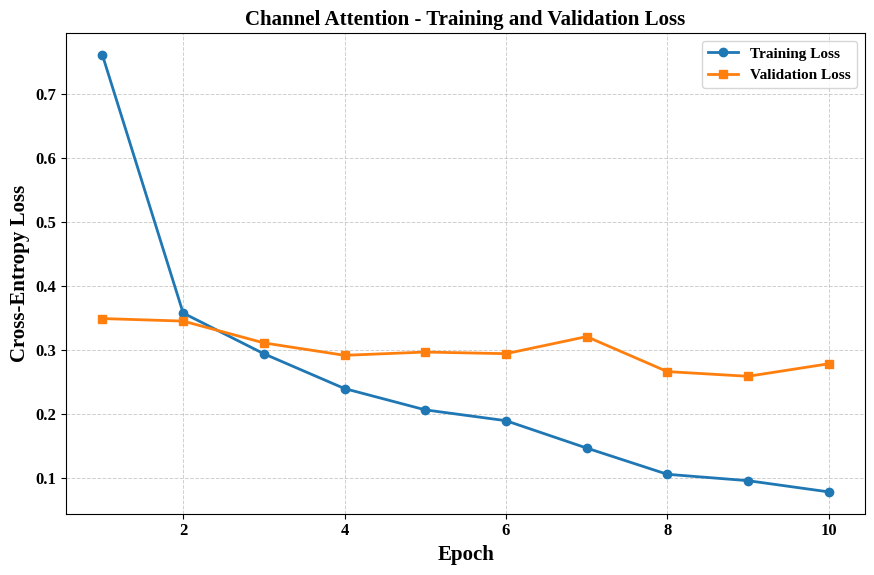


Experiment: exp1_attention_channel
Model: exp1_attention_channel
Accuracy: 0.9274047186932849
Precision: 0.9258303970375712
Recall: 0.9292418546365916
Macro_F1: 0.9264894902307343
Trainable_Parameters: 15095877
Total_Parameters: 23730117
Inference_ms_per_image: 8.709450265624715
Saved: /content/resnet50_attention_results/plots/exp1_attention_channel_confusion_matrix.png


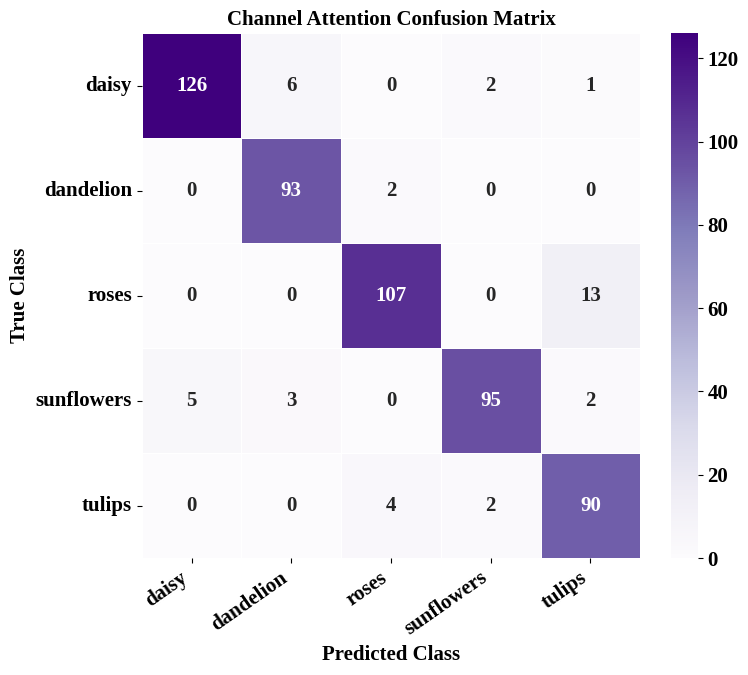


Training: exp1_attention_spatial
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 242ms/step - accuracy: 0.5426 - loss: 1.1029 - val_accuracy: 0.8745 - val_loss: 0.3487 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - accuracy: 0.8544 - loss: 0.4182 - val_accuracy: 0.9109 - val_loss: 0.2649 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.8789 - loss: 0.3301 - val_accuracy: 0.9145 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.9097 - loss: 0.2557 - val_accuracy: 0.9127 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.9101 - loss: 0.2445 - val_accuracy: 0.9109 - val_loss: 0.2428 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 276ms/step - accuracy: 0.9245 - loss: 0.2107 - val_accuracy: 0.9182 - 

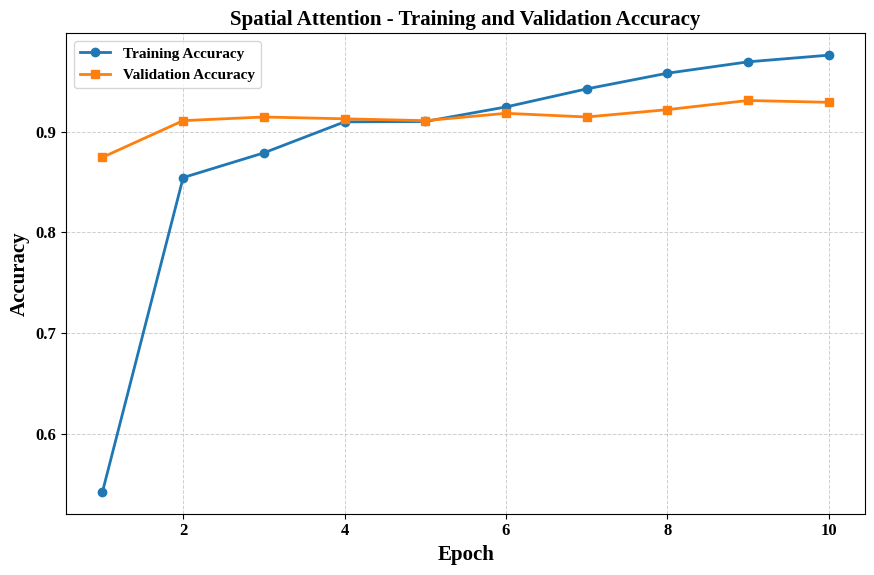

Saved: /content/resnet50_attention_results/plots/exp1_attention_spatial_loss.png


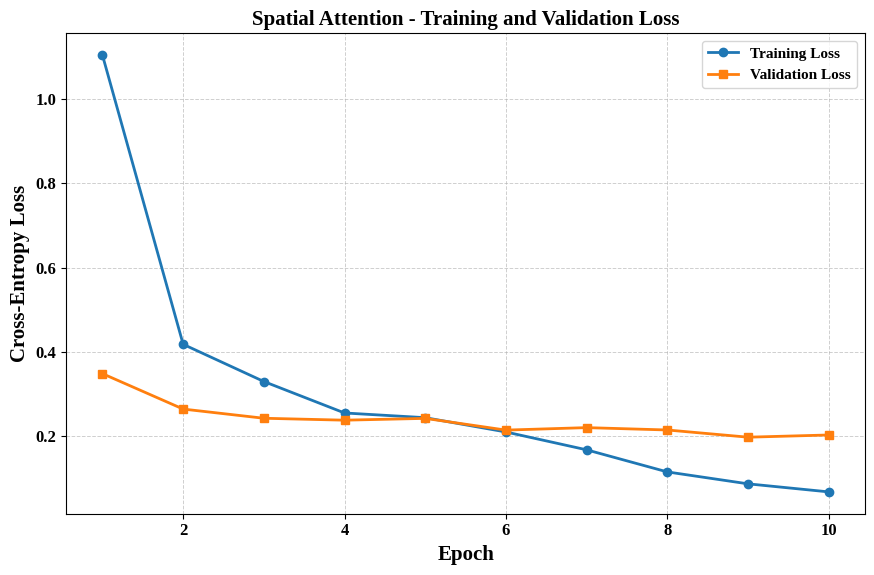


Experiment: exp1_attention_spatial
Model: exp1_attention_spatial
Accuracy: 0.9382940108892922
Precision: 0.9374935384270028
Recall: 0.9380029935950989
Macro_F1: 0.937718653443944
Trainable_Parameters: 14963816
Total_Parameters: 23598056
Inference_ms_per_image: 8.175056835416683
Saved: /content/resnet50_attention_results/plots/exp1_attention_spatial_confusion_matrix.png


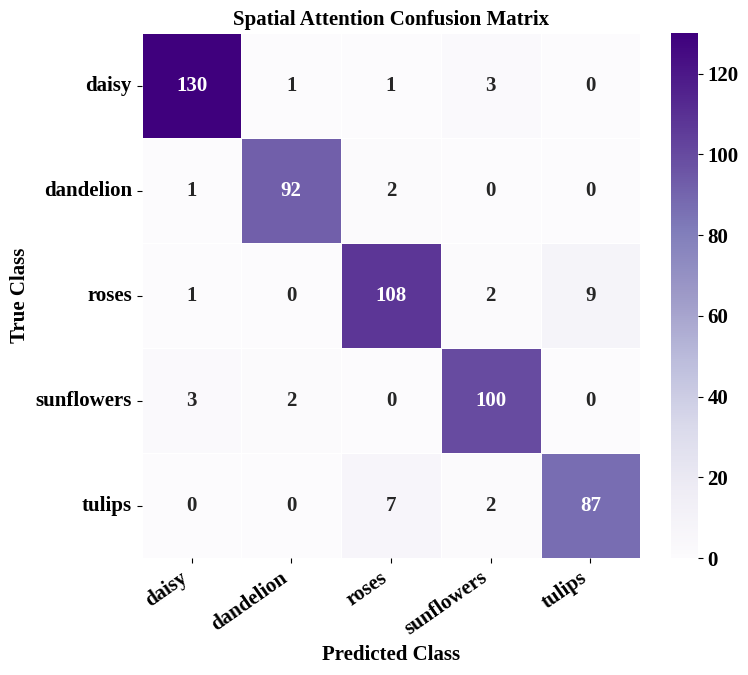


Training: exp1_attention_channel_spatial
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 252ms/step - accuracy: 0.6835 - loss: 0.8250 - val_accuracy: 0.8673 - val_loss: 0.3587 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 37s 206ms/step - accuracy: 0.8743 - loss: 0.3483 - val_accuracy: 0.8945 - val_loss: 0.3063 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 212ms/step - accuracy: 0.8992 - loss: 0.2845 - val_accuracy: 0.9127 - val_loss: 0.2645 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 207ms/step - accuracy: 0.9144 - loss: 0.2283 - val_accuracy: 0.9073 - val_loss: 0.2813 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9244 - loss: 0.2182
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 204ms/step - accuracy: 0.9311 - loss: 0.2011 - val_accuracy: 0.9018 - val_loss: 0.2945 - learning_rate: 0.0010
Restoring model weights from the end of the bes

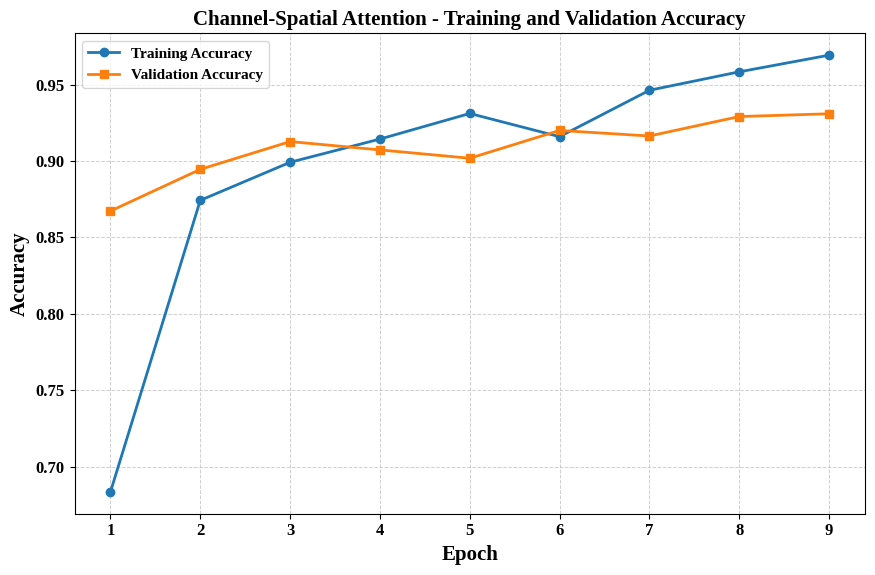

Saved: /content/resnet50_attention_results/plots/exp1_attention_channel_spatial_loss.png


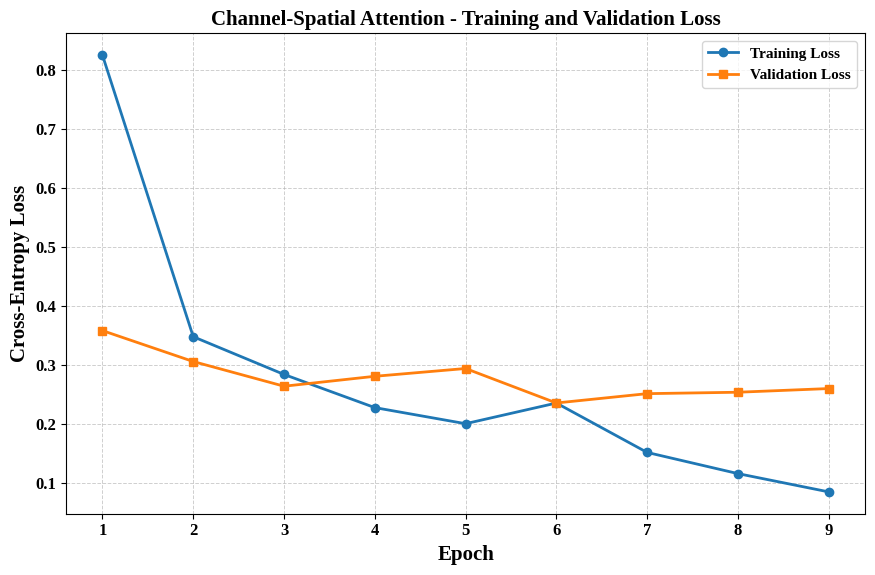


Experiment: exp1_attention_channel_spatial
Model: exp1_attention_channel_spatial
Accuracy: 0.9274047186932849
Precision: 0.9258002935393094
Recall: 0.9281927039821778
Macro_F1: 0.9268200152134917
Trainable_Parameters: 15095976
Total_Parameters: 23730216
Inference_ms_per_image: 8.819991765625446
Saved: /content/resnet50_attention_results/plots/exp1_attention_channel_spatial_confusion_matrix.png


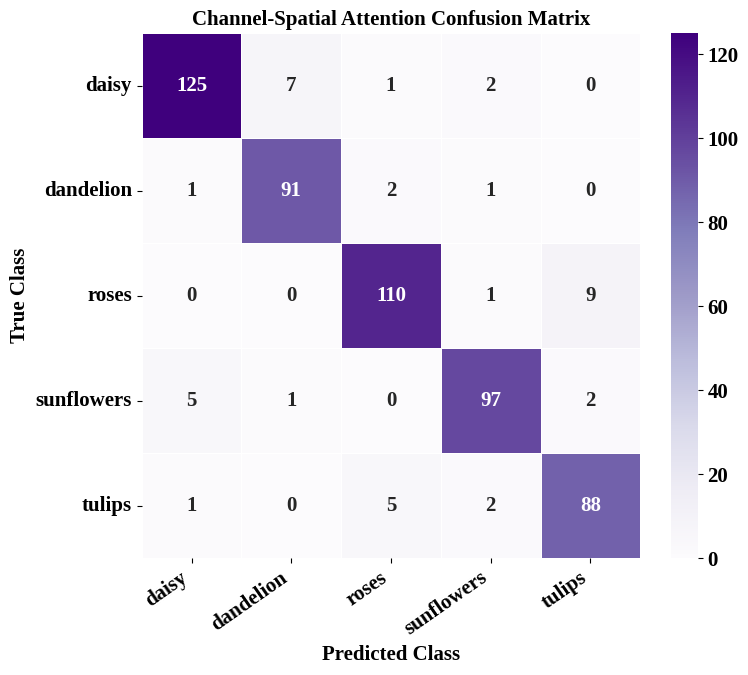


Training: exp1_attention_self
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 260ms/step - accuracy: 0.7077 - loss: 0.8185 - val_accuracy: 0.8982 - val_loss: 0.2945 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 219ms/step - accuracy: 0.8867 - loss: 0.3122 - val_accuracy: 0.8945 - val_loss: 0.2697 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 217ms/step - accuracy: 0.9128 - loss: 0.2380 - val_accuracy: 0.9418 - val_loss: 0.2072 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 208ms/step - accuracy: 0.9373 - loss: 0.1752 - val_accuracy: 0.9018 - val_loss: 0.2493 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9334 - loss: 0.1831
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - accuracy: 0.9319 - loss: 0.1762 - val_accuracy: 0.9127 - val_loss: 0.2250 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.

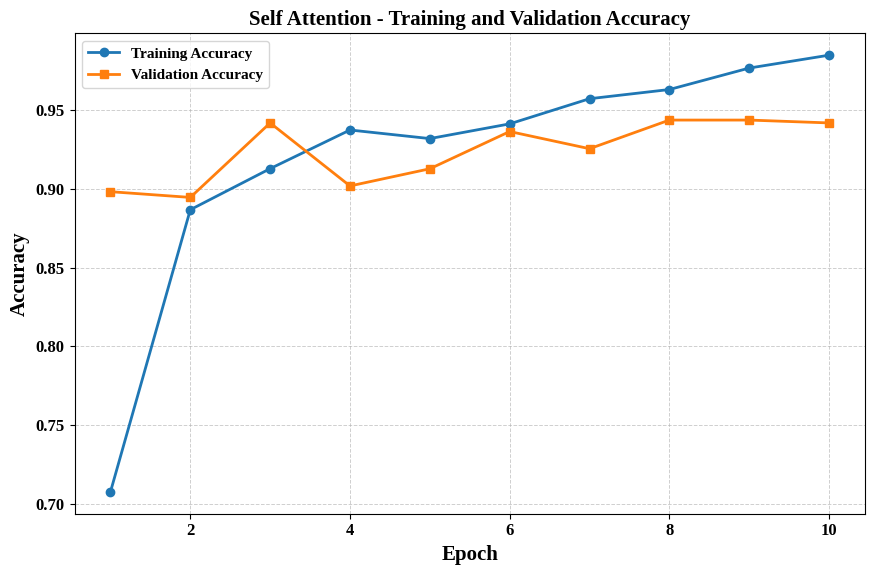

Saved: /content/resnet50_attention_results/plots/exp1_attention_self_loss.png


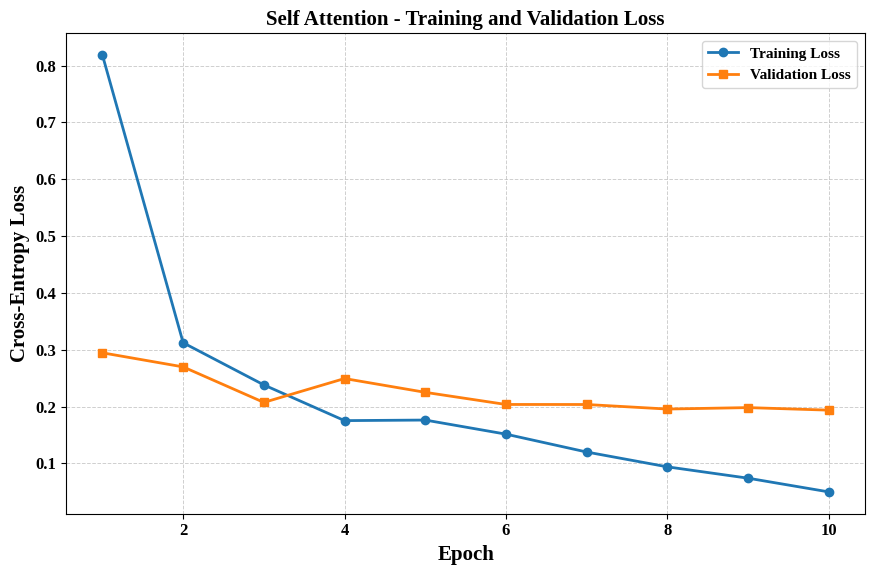


Experiment: exp1_attention_self
Model: exp1_attention_self
Accuracy: 0.9292196007259528
Precision: 0.9298851692230301
Recall: 0.928291910331384
Macro_F1: 0.9289904343571298
Trainable_Parameters: 15489414
Total_Parameters: 24123654
Inference_ms_per_image: 8.731578963541628
Saved: /content/resnet50_attention_results/plots/exp1_attention_self_confusion_matrix.png


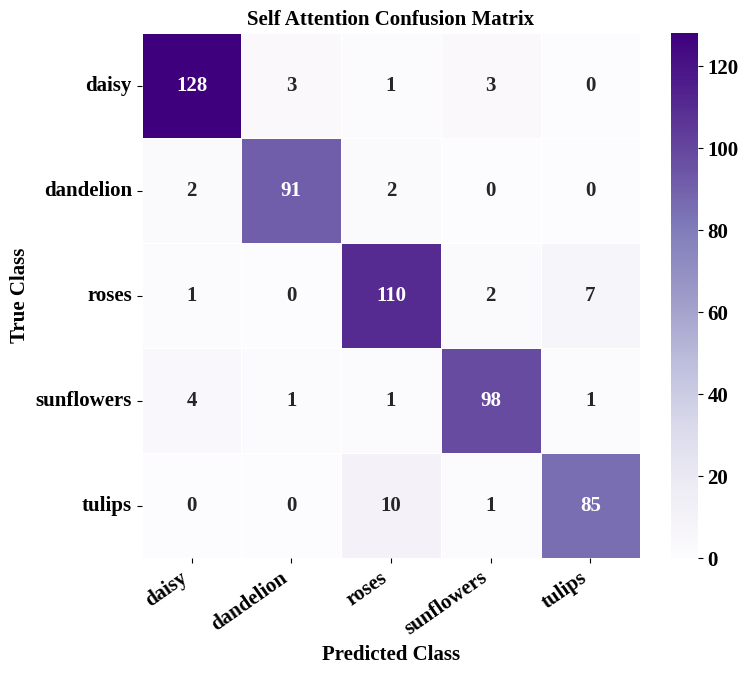

In [ ]:
import gc
import tensorflow as tf

# ============================================================
# EXPERIMENT 1: ATTENTION-TYPE ABLATION AT P3 (FULL SUITE)
# ============================================================

attention_type_results = {}

# Safely initialize the global results list if it doesn't exist
if "results" not in globals():
    results = []

# The baseline is already trained.
attention_type_results["baseline"] = {
    "result": baseline_result,
    "history": baseline_history
    # NOTE: Omit storing raw baseline_model here to conserve RAM
}

# Ensure baseline results are in the results list
if baseline_result not in results:
    results.append(baseline_result)

# Set to True for the full experiment suite.
RUN_ALL_ATTENTION_TYPES = True

# Mapping short keys to formal supertitles
attention_display_names = {
    "channel": "Channel Attention",
    "spatial": "Spatial Attention",
    "channel_spatial": "Channel-Spatial Attention",
    "self": "Self Attention"
}

if RUN_ALL_ATTENTION_TYPES:

    # 1. Back up original functions ONCE outside the loop to prevent re-wrapping recursion
    _backup_orig_plot_acc = plot_accuracy_history
    _backup_orig_plot_loss = plot_loss_history
    _backup_orig_plot_cm = plot_confusion_matrix

    try:
        for attention_type in [
            "channel",
            "spatial",
            "channel_spatial",
            "self"
        ]:
            # Retrieve the clean display name for plots
            display_name = attention_display_names.get(attention_type, attention_type.title())
            file_prefix = f"exp1_attention_{attention_type}"

            # 2. Dynamically override globals using strict parameter bindings
            globals()["plot_accuracy_history"] = (
                lambda hist, filename, expt=None, title=display_name, fn=_backup_orig_plot_acc:
                fn(hist, filename, expt=title)
            )
            globals()["plot_loss_history"] = (
                lambda hist, filename, expt=None, title=display_name, fn=_backup_orig_plot_loss:
                fn(hist, filename, expt=title)
            )
            globals()["plot_confusion_matrix"] = (
                lambda cm, title, filename, name=display_name, fn=_backup_orig_plot_cm:
                fn(cm, f"{name} Confusion Matrix", filename)
            )

            # Run experiment
            experiment = run_experiment(
                experiment_name=file_prefix,
                attention_type=attention_type,
                position="P3"
            )

            # Store only lightweight metadata (metrics + history) to prevent RAM inflation
            attention_type_results[file_prefix] = {
                "result": experiment.get("result"),
                "history": experiment.get("history")
            }

            if "result" in experiment:
                results.append(experiment["result"])

            # ------------------------------------------------------------
            # COMPLETE MEMORY & VRAM PURGE BETWEEN ITERATIONS
            # ------------------------------------------------------------
            # Delete local experiment references explicitly
            del experiment

            # Clear Keras global graph and execution state
            tf.keras.backend.clear_session()

            # Force Python garbage collector to reclaim unreferenced GPU tensors
            gc.collect()

    finally:
        # 3. Always restore original plotting functions
        globals()["plot_accuracy_history"] = _backup_orig_plot_acc
        globals()["plot_loss_history"] = _backup_orig_plot_loss
        globals()["plot_confusion_matrix"] = _backup_orig_plot_cm


>>> Starting Additional Attention Experiment: squeeze_and_excitation_attention_p3 <<<

Training: squeeze_and_excitation_attention_p3
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 239ms/step - accuracy: 0.7003 - loss: 0.7842 - val_accuracy: 0.8691 - val_loss: 0.3740 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 206ms/step - accuracy: 0.8641 - loss: 0.3656 - val_accuracy: 0.8818 - val_loss: 0.3089 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 200ms/step - accuracy: 0.8941 - loss: 0.2887 - val_accuracy: 0.9000 - val_loss: 0.2857 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.9112 - loss: 0.2395 - val_accuracy: 0.9255 - val_loss: 0.2631 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.9237 - loss: 0.2156 - val_accuracy: 0.9145 - val_loss: 0.2627 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epoch 1/5
8

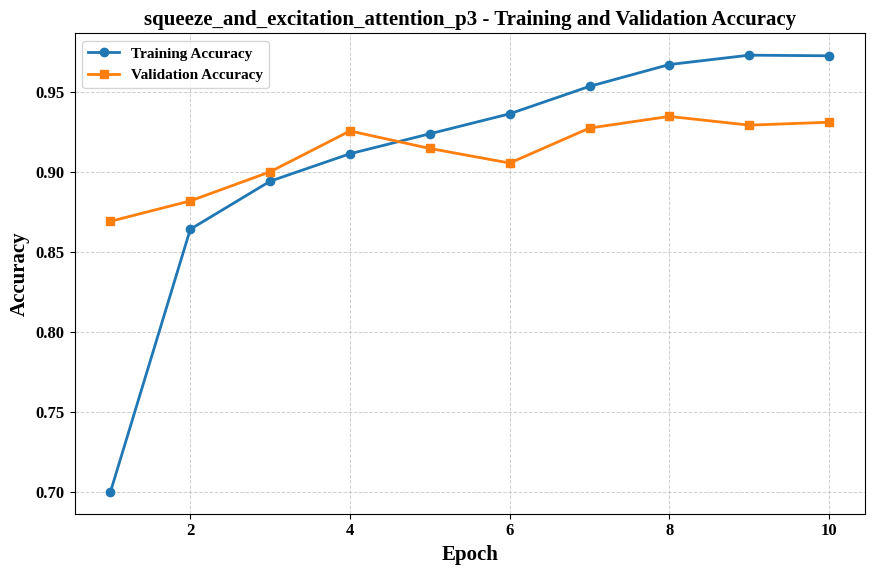

Saved: /content/resnet50_attention_results/plots/squeeze_and_excitation_attention_p3_loss.png


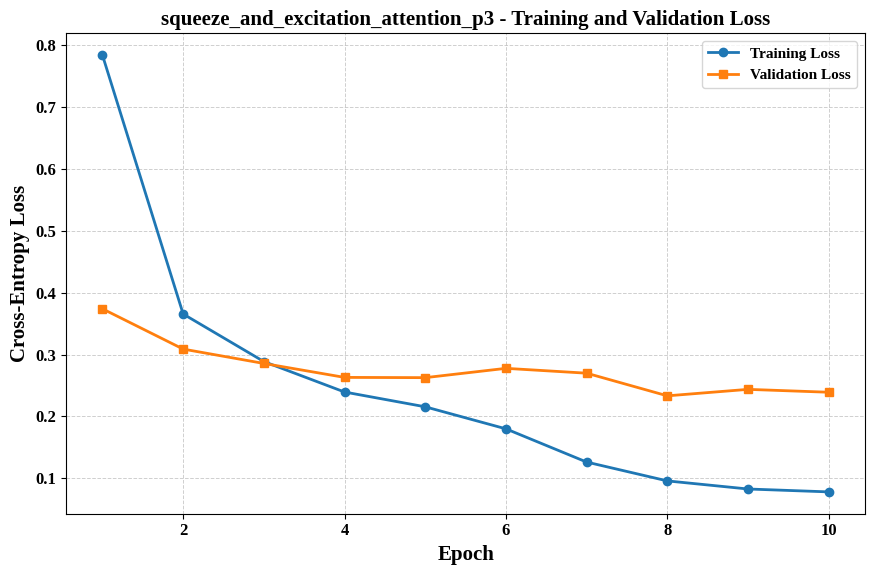


Experiment: squeeze_and_excitation_attention_p3
Model: squeeze_and_excitation_attention_p3
Accuracy: 0.9401088929219601
Precision: 0.9379688398092592
Recall: 0.9421076998050684
Macro_F1: 0.9393834701057816
Trainable_Parameters: 15095877
Total_Parameters: 23730117
Inference_ms_per_image: 8.789551219791747
Saved: /content/resnet50_attention_results/plots/squeeze_and_excitation_attention_p3_confusion_matrix.png


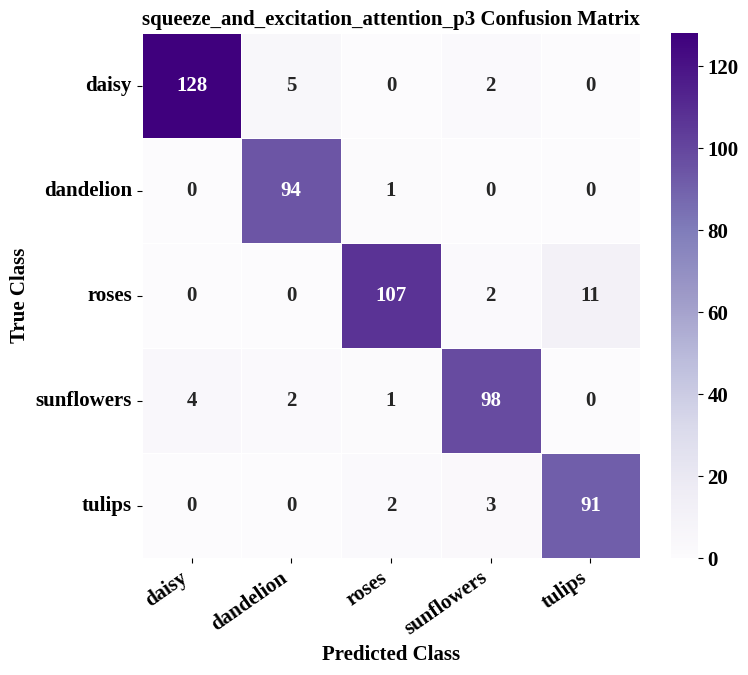


>>> Starting Additional Attention Experiment: convolutional_block_attention_module_p3 <<<

Training: convolutional_block_attention_module_p3
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 245ms/step - accuracy: 0.7240 - loss: 0.7358 - val_accuracy: 0.8782 - val_loss: 0.3530 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.8786 - loss: 0.3394 - val_accuracy: 0.9000 - val_loss: 0.2745 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - accuracy: 0.8996 - loss: 0.2818 - val_accuracy: 0.9109 - val_loss: 0.2542 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - accuracy: 0.9202 - loss: 0.2239 - val_accuracy: 0.9036 - val_loss: 0.2438 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - accuracy: 0.9268 - loss: 0.2089 - val_accuracy: 0.9127 - val_loss: 0.2393 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epo

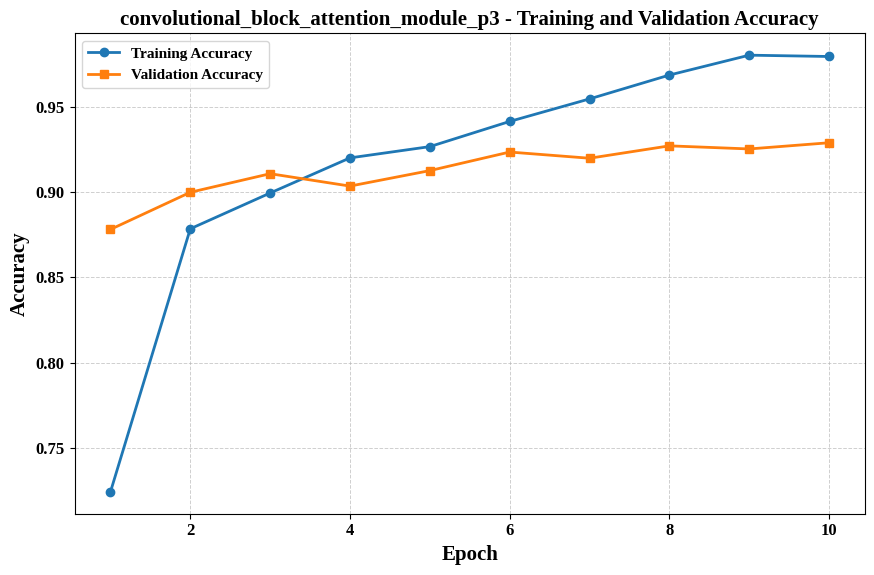

Saved: /content/resnet50_attention_results/plots/convolutional_block_attention_module_p3_loss.png


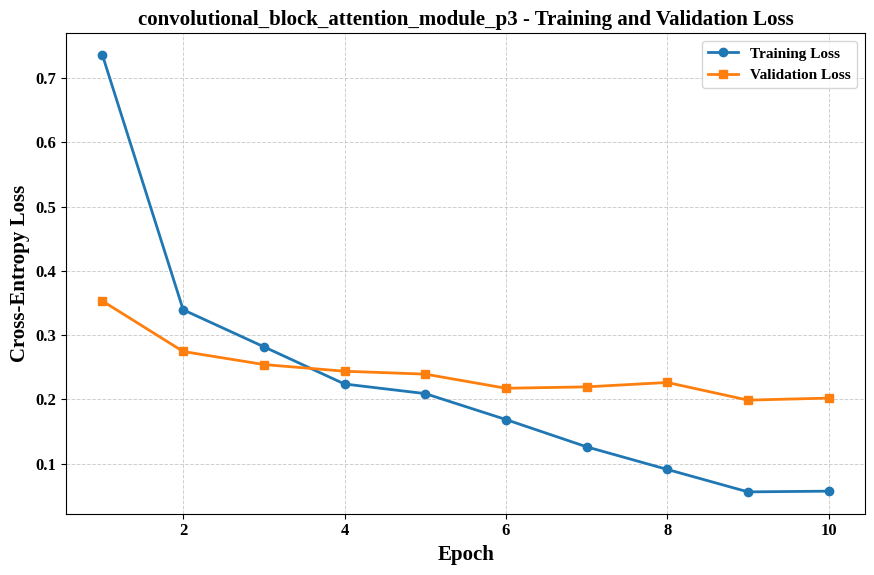


Experiment: convolutional_block_attention_module_p3
Model: convolutional_block_attention_module_p3
Accuracy: 0.925589836660617
Precision: 0.9246425972981088
Recall: 0.9257720690615427
Macro_F1: 0.9241350931523712
Trainable_Parameters: 15095976
Total_Parameters: 23730216
Inference_ms_per_image: 9.199152200000071
Saved: /content/resnet50_attention_results/plots/convolutional_block_attention_module_p3_confusion_matrix.png


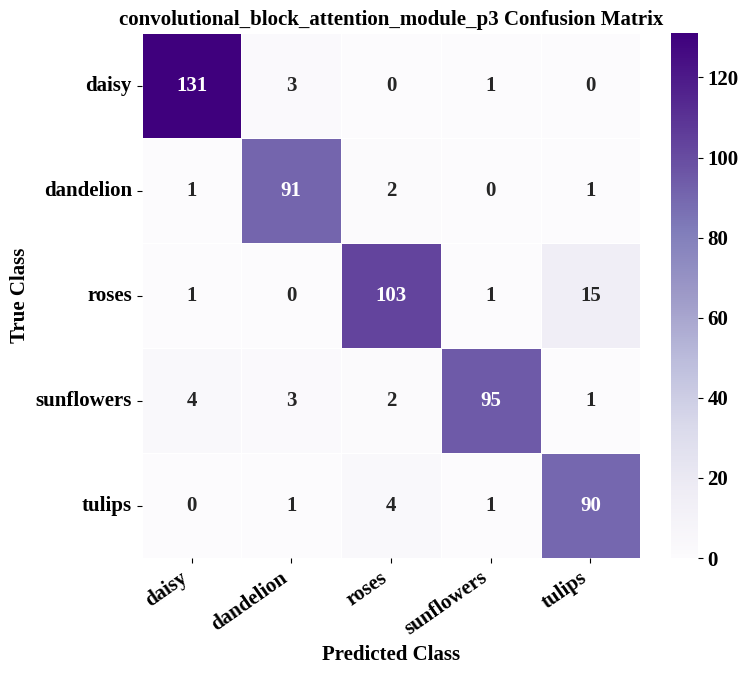

In [ ]:
# ============================================================
# ADDITIONAL ATTENTION MECHANISMS
# ============================================================

RUN_ADDITIONAL_ATTENTION = True

if RUN_ADDITIONAL_ATTENTION:

    # Ensuring the results collection objects exist globally
    if "attention_type_results" not in globals():
        attention_type_results = {}
    if "results" not in globals():
        results = []

    # Mapping the short attention types to fully unabbreviated names for experiments
    full_attention_names = {
        "se": "squeeze_and_excitation_attention",
        # "eca": "efficient_channel_attention",
        "cbam": "convolutional_block_attention_module",
        # "coordinate": "coordinate_attention"
    }

    for attention_type in [
        "se",
        # "eca",
        "cbam",
        # "coordinate"
    ]:

        # Use unabbreviated, explicit naming as requested
        unabbreviated_name = full_attention_names[attention_type]
        experiment_name = f"{unabbreviated_name}_p3"
        print(f"\n>>> Starting Additional Attention Experiment: {experiment_name} <<<")

        try:
            # Safeguard if run_experiment is missing in active scope
            if "run_experiment" not in globals():
                raise NameError("The function 'run_experiment' is not defined. Please run the cell containing its definition first (VvZ8bgIIowJV).")

            experiment = run_experiment(
                experiment_name=experiment_name,
                attention_type=attention_type,
                position="P3"
            )

            # Save only lightweight metadata to avoid serialization or RAM inflation issues
            attention_type_results[experiment_name] = {
                "result": experiment.get("result"),
                "history": experiment.get("history")
            }

            if "result" in experiment and experiment["result"] is not None:
                results.append(experiment["result"])

        except Exception as e:
            print(f"\nError during experiment {experiment_name}: {e}")
            print("This is likely due to Keras serialization limitations with dynamic slicing inside the Coordinate Attention Lambda layers.")


In [ ]:
# ============================================================
# SAVE RESULTS
# ============================================================

def save_results(results, filename="all_experiment_results.csv"):

    results_df = pd.DataFrame(results)

    results_df.to_csv(
        os.path.join(
            RESULT_DIR,
            filename
        ),
        index=False
    )

    print(results_df.to_string(index=False))

    return results_df



In [ ]:
results_df = save_results(results)

                                  Model  Accuracy  Precision   Recall  Macro_F1  Trainable_Parameters  Total_Parameters  Inference_ms_per_image
                               baseline  0.911071   0.909538 0.911965  0.909704                 10245          23597957                8.634830
                 exp1_attention_channel  0.927405   0.925830 0.929242  0.926489              15095877          23730117                8.709450
                 exp1_attention_spatial  0.938294   0.937494 0.938003  0.937719              14963816          23598056                8.175057
         exp1_attention_channel_spatial  0.927405   0.925800 0.928193  0.926820              15095976          23730216                8.819992
                    exp1_attention_self  0.929220   0.929885 0.928292  0.928990              15489414          24123654                8.731579
    squeeze_and_excitation_attention_p3  0.940109   0.937969 0.942108  0.939383              15095877          23730117                8

In [ ]:
results=[]


Training: channel_spatial_P2
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 275ms/step - accuracy: 0.2160 - loss: 1.7633 - val_accuracy: 0.3764 - val_loss: 1.3741 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 37s 232ms/step - accuracy: 0.6582 - loss: 0.8817 - val_accuracy: 0.8309 - val_loss: 0.4709 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 234ms/step - accuracy: 0.8143 - loss: 0.5057 - val_accuracy: 0.8618 - val_loss: 0.3809 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 231ms/step - accuracy: 0.8758 - loss: 0.3584 - val_accuracy: 0.8855 - val_loss: 0.3152 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 227ms/step - accuracy: 0.8852 - loss: 0.3146 - val_accuracy: 0.8964 - val_loss: 0.3006 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 312ms/step - accuracy: 0.9124 - loss: 0.2479 - val_accuracy: 0.9091 - val_

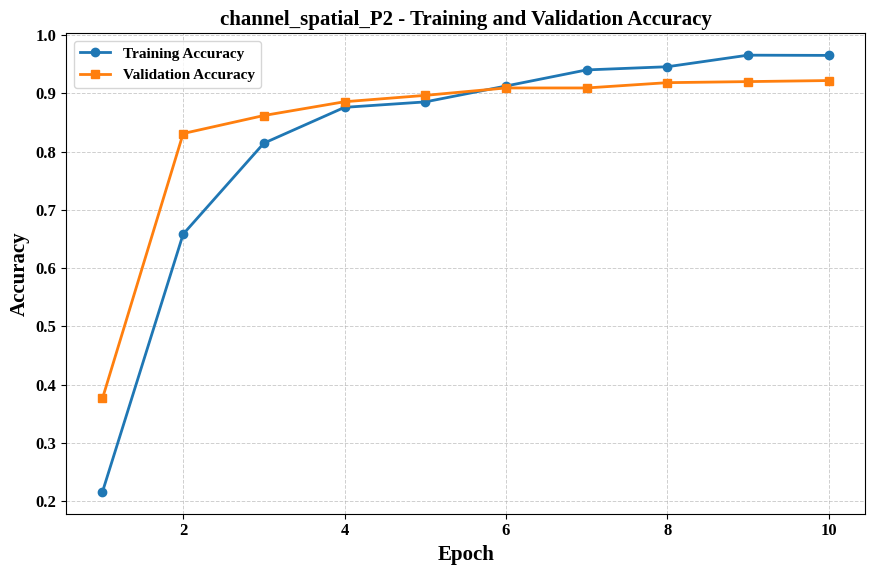

Saved: /content/resnet50_attention_results/plots/channel_spatial_P2_loss.png


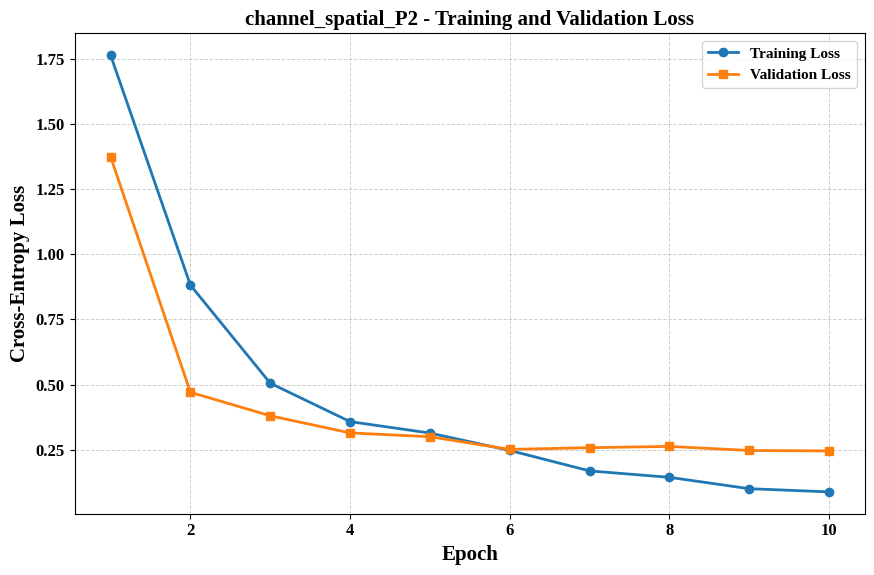


Experiment: channel_spatial_P2
Model: channel_spatial_P2
Accuracy: 0.9128856624319419
Precision: 0.9124053387769925
Recall: 0.91448029796714
Macro_F1: 0.9129229938133875
Trainable_Parameters: 14997128
Total_Parameters: 23631368
Inference_ms_per_image: 9.122618105208366
Saved: /content/resnet50_attention_results/plots/channel_spatial_P2_confusion_matrix.png


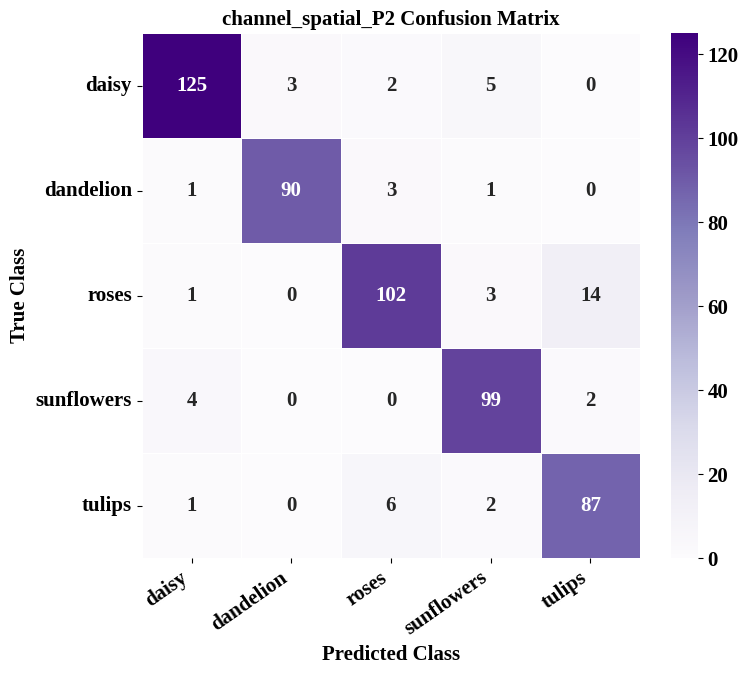


Training: channel_spatial_P3
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 249ms/step - accuracy: 0.6699 - loss: 0.8480 - val_accuracy: 0.8982 - val_loss: 0.3254 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.8758 - loss: 0.3494 - val_accuracy: 0.9018 - val_loss: 0.2922 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 198ms/step - accuracy: 0.8988 - loss: 0.2893 - val_accuracy: 0.9055 - val_loss: 0.2658 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 194ms/step - accuracy: 0.9194 - loss: 0.2271 - val_accuracy: 0.9036 - val_loss: 0.2833 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 196ms/step - accuracy: 0.9257 - loss: 0.2105 - val_accuracy: 0.9109 - val_loss: 0.2489 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 276ms/step - accuracy: 0.9327 - loss: 0.1783 - val_accuracy: 0.9200 - val_

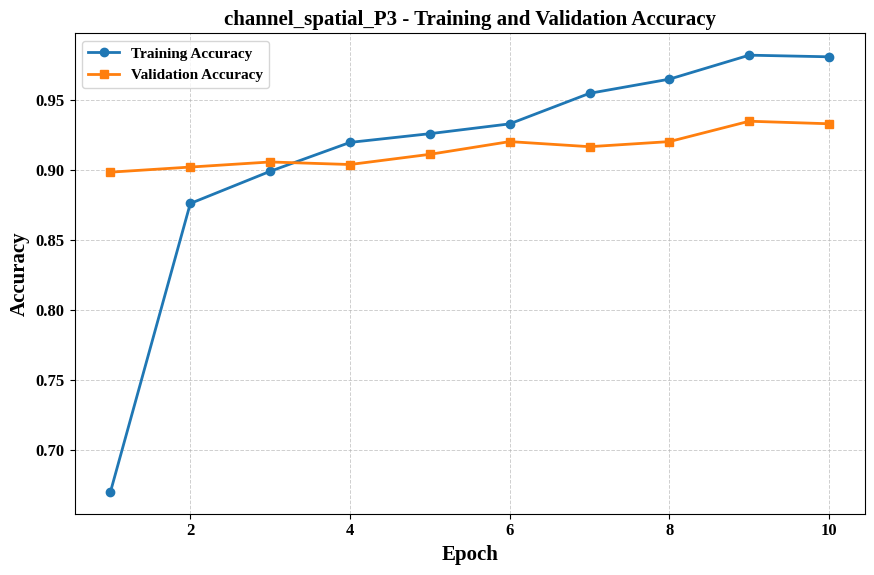

Saved: /content/resnet50_attention_results/plots/channel_spatial_P3_loss.png


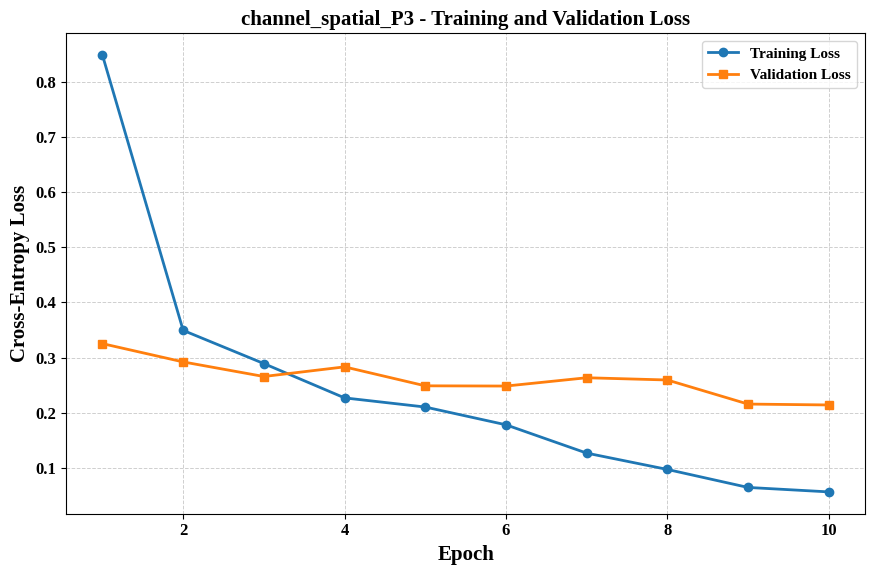


Experiment: channel_spatial_P3
Model: channel_spatial_P3
Accuracy: 0.9292196007259528
Precision: 0.9272738275962599
Recall: 0.930776246170983
Macro_F1: 0.928019227088216
Trainable_Parameters: 15095976
Total_Parameters: 23730216
Inference_ms_per_image: 9.571529469791546
Saved: /content/resnet50_attention_results/plots/channel_spatial_P3_confusion_matrix.png


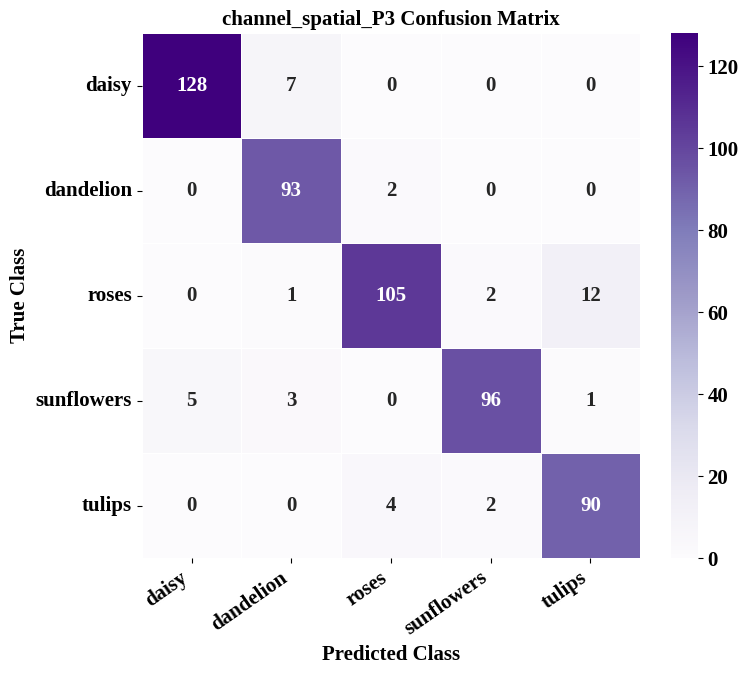


Training: channel_spatial_P4
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 227ms/step - accuracy: 0.7844 - loss: 0.5927 - val_accuracy: 0.9109 - val_loss: 0.2586 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 188ms/step - accuracy: 0.9007 - loss: 0.2863 - val_accuracy: 0.9273 - val_loss: 0.2305 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 185ms/step - accuracy: 0.9221 - loss: 0.2173 - val_accuracy: 0.9200 - val_loss: 0.2228 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 179ms/step - accuracy: 0.9447 - loss: 0.1550 - val_accuracy: 0.9182 - val_loss: 0.2466 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.9536 - loss: 0.1309
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 180ms/step - accuracy: 0.9583 - loss: 0.1225 - val_accuracy: 0.9109 - val_loss: 0.2589 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.


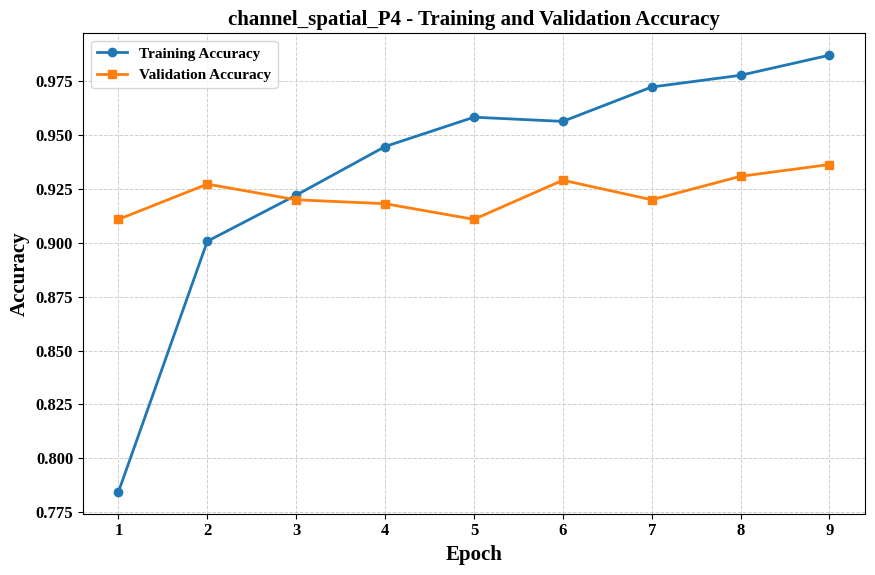

Saved: /content/resnet50_attention_results/plots/channel_spatial_P4_loss.png


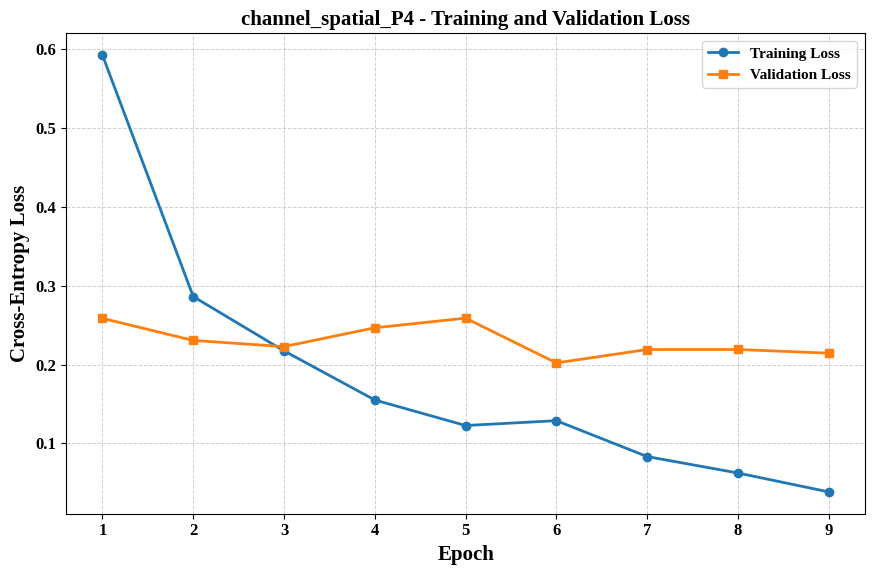


Experiment: channel_spatial_P4
Model: channel_spatial_P4
Accuracy: 0.925589836660617
Precision: 0.9246107548711076
Recall: 0.924193469785575
Macro_F1: 0.9238487141001196
Trainable_Parameters: 15490280
Total_Parameters: 24124520
Inference_ms_per_image: 9.652421123958277
Saved: /content/resnet50_attention_results/plots/channel_spatial_P4_confusion_matrix.png


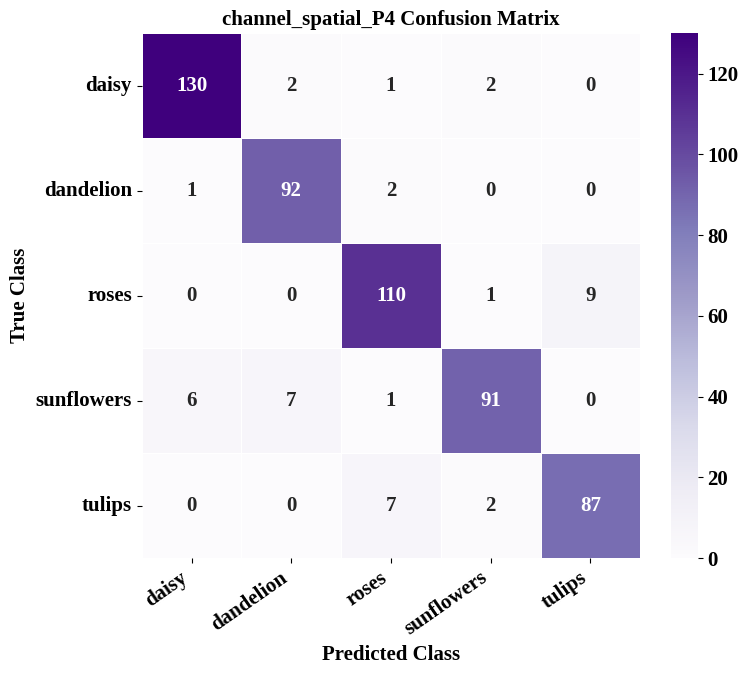

NameError: name 'save_results' is not defined

In [ ]:
# ============================================================
# EXPERIMENT 2: ATTENTION-POSITION ABLATION
# ============================================================

position_results = {}

# Run the ablation for all three key positions
positions_to_run = ["P2", "P3", "P4"]

# Ensure results is initialized as a list
if "results" not in globals() or not isinstance(results, list):
    results = []

for position in positions_to_run:
    experiment_name = f"channel_spatial_{position}"


    experiment = run_experiment(
        experiment_name=experiment_name,
        attention_type="channel_spatial",
        position=position
    )

    if experiment.get("result") not in results:
        results.append(
            experiment["result"]
        )

    position_results[position] = experiment

In [ ]:
position_results_df = save_results(
    [
        position_results[p]["result"]
        for p in position_results
        if position_results[p].get("result") is not None
    ],
    filename="attention_position_results.csv"
)

             Model  Accuracy  Precision   Recall  Macro_F1  Trainable_Parameters  Total_Parameters  Inference_ms_per_image
channel_spatial_P2  0.912886   0.912405 0.914480  0.912923              14997128          23631368                9.122618
channel_spatial_P3  0.929220   0.927274 0.930776  0.928019              15095976          23730216                9.571529
channel_spatial_P4  0.925590   0.924611 0.924193  0.923849              15490280          24124520                9.652421


Saved: /content/resnet50_attention_results/plots/attention_position_accuracy.png


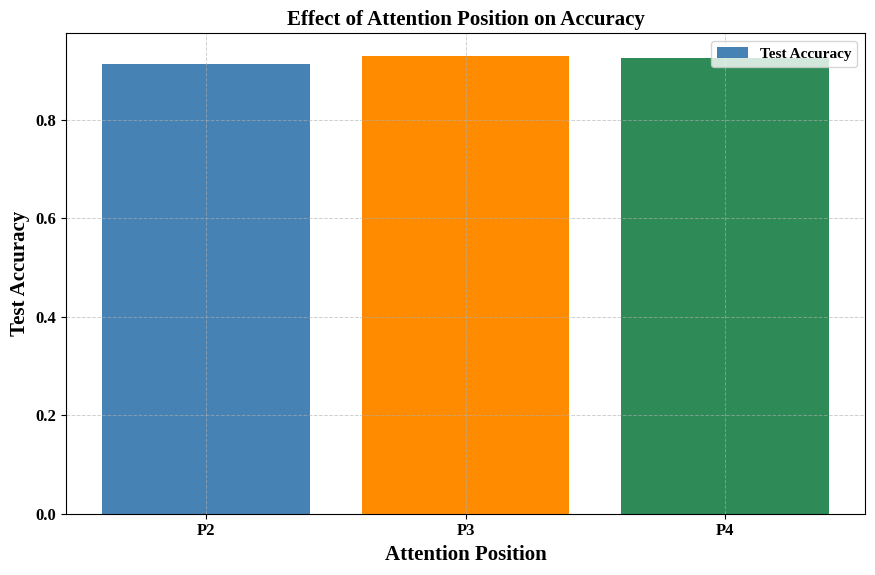

In [ ]:
# ============================================================
# POSITION VS ACCURACY
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

positions = list(position_results.keys())

accuracies = [
    position_results[p]["result"]["Accuracy"]
    for p in positions
]

ax.bar(
    positions,
    accuracies,
    color=["steelblue", "darkorange", "seagreen"],
    label="Test Accuracy"
)

finish_plot(
    ax,
    "Effect of Attention Position on Accuracy",
    "Attention Position",
    "Test Accuracy"
)

fig.tight_layout()

save_plot(
    fig,
    "attention_position_accuracy.png"
)

plt.show()

Saved: /content/resnet50_attention_results/plots/attention_position_macro_f1.png


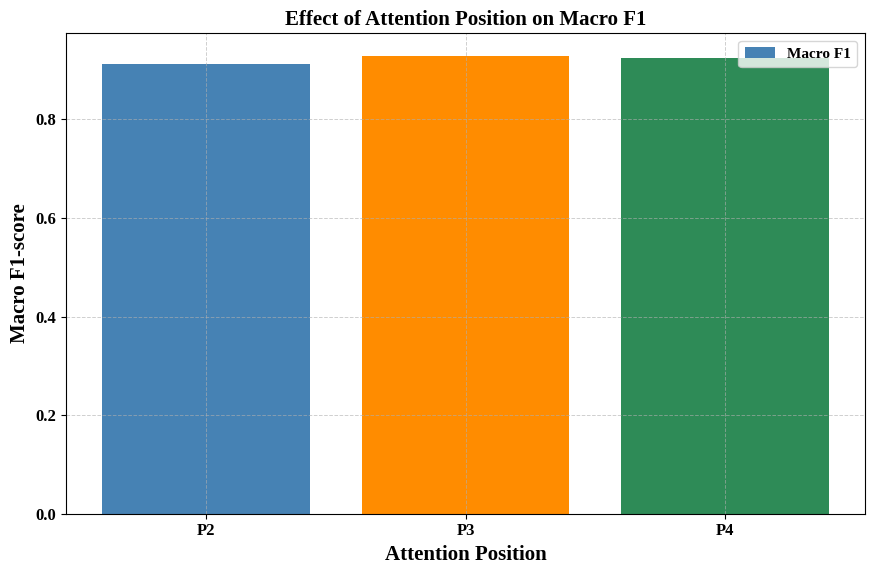

In [ ]:
# ============================================================
# POSITION VS MACRO F1
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

f1_values = [
    position_results[p]["result"]["Macro_F1"]
    for p in positions
]

ax.bar(
    positions,
    f1_values,
    color=["steelblue", "darkorange", "seagreen"],
    label="Macro F1"
)

finish_plot(
    ax,
    "Effect of Attention Position on Macro F1",
    "Attention Position",
    "Macro F1-score"
)

fig.tight_layout()

save_plot(
    fig,
    "attention_position_macro_f1.png"
)

plt.show()

In [ ]:
# ============================================================
# EXTENDED POSITION EXPERIMENT
# ============================================================

RUN_P1_EXPERIMENT = False

if RUN_P1_EXPERIMENT:

    experiment_p1 = run_experiment(
        experiment_name="channel_spatial_P1",
        attention_type="channel_spatial",
        position="P1"
    )

    position_results["P1"] = experiment_p1

    results.append(
        experiment_p1["result"]
    )


Training: multi_P3_P4
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 40s 257ms/step - accuracy: 0.5037 - loss: 1.1339 - val_accuracy: 0.8309 - val_loss: 0.4943 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.8556 - loss: 0.3800 - val_accuracy: 0.8800 - val_loss: 0.3770 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 203ms/step - accuracy: 0.8984 - loss: 0.2780 - val_accuracy: 0.9018 - val_loss: 0.3007 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.9268 - loss: 0.2067 - val_accuracy: 0.9091 - val_loss: 0.2862 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - accuracy: 0.9451 - loss: 0.1560 - val_accuracy: 0.9036 - val_loss: 0.3069 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 276ms/step - accuracy: 0.9471 - loss: 0.1422 - val_accuracy: 0.8964 - val_loss: 0

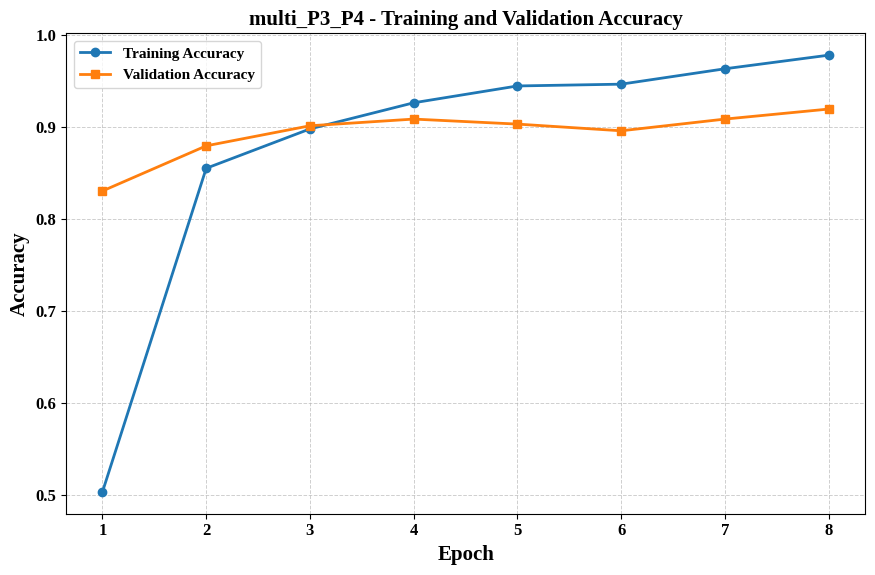

Saved: /content/resnet50_attention_results/plots/multi_P3_P4_loss.png


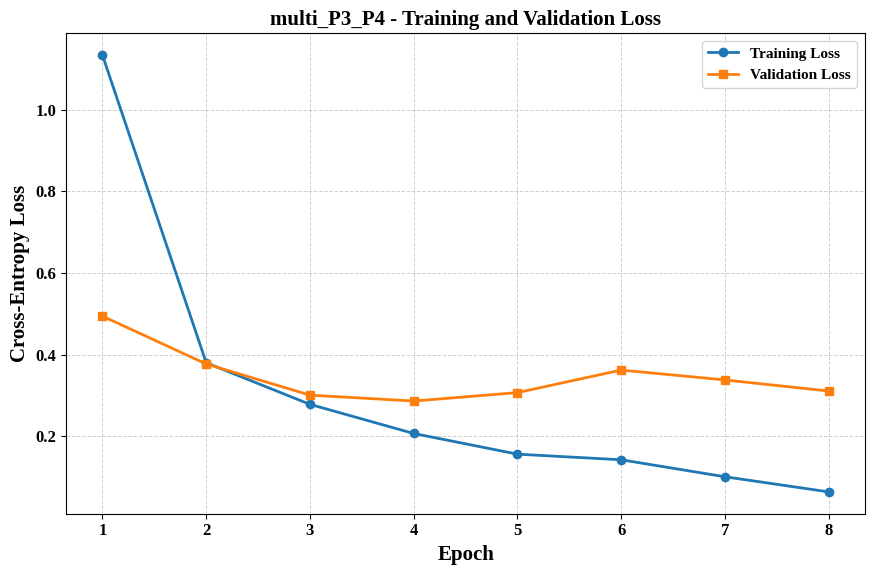


Experiment: multi_P3_P4
Model: multi_P3_P4
Accuracy: 0.9001814882032668
Precision: 0.9034829086302381
Recall: 0.9017286271233639
Macro_F1: 0.8986929472643759
Trainable_Parameters: 15622539
Total_Parameters: 24256779
Inference_ms_per_image: 9.944364568750075
Saved: /content/resnet50_attention_results/plots/multi_P3_P4_confusion_matrix.png


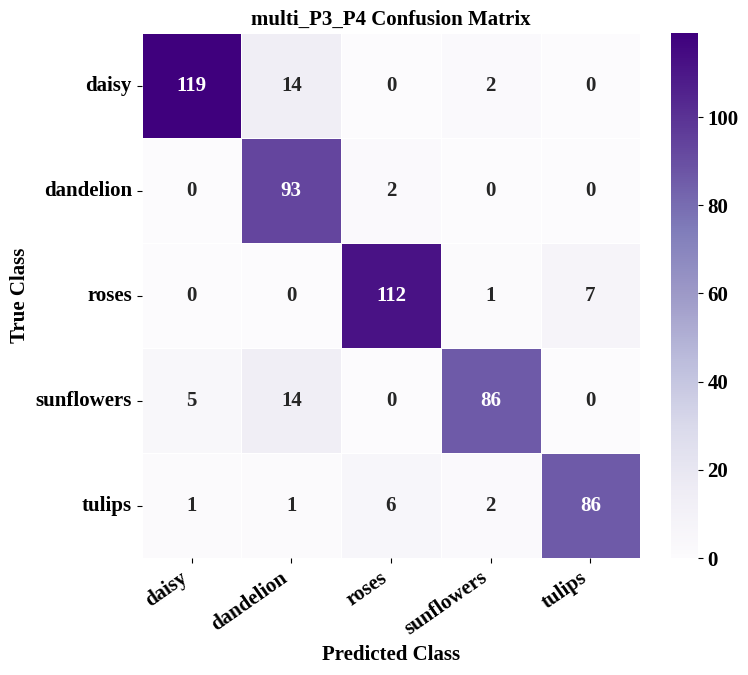


Training: multi_P2_P3_P4
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 36s 297ms/step - accuracy: 0.6069 - loss: 0.9568 - val_accuracy: 0.8364 - val_loss: 0.4732 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 249ms/step - accuracy: 0.8408 - loss: 0.4229 - val_accuracy: 0.8873 - val_loss: 0.3312 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 241ms/step - accuracy: 0.8875 - loss: 0.3112 - val_accuracy: 0.8909 - val_loss: 0.3357 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 241ms/step - accuracy: 0.9155 - loss: 0.2334 - val_accuracy: 0.8964 - val_loss: 0.3246 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 239ms/step - accuracy: 0.9284 - loss: 0.1937 - val_accuracy: 0.8745 - val_loss: 0.4130 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 37s 311ms/step - accuracy: 0.9342 - loss: 0.1746 - val_accuracy: 0.9200 - val_loss

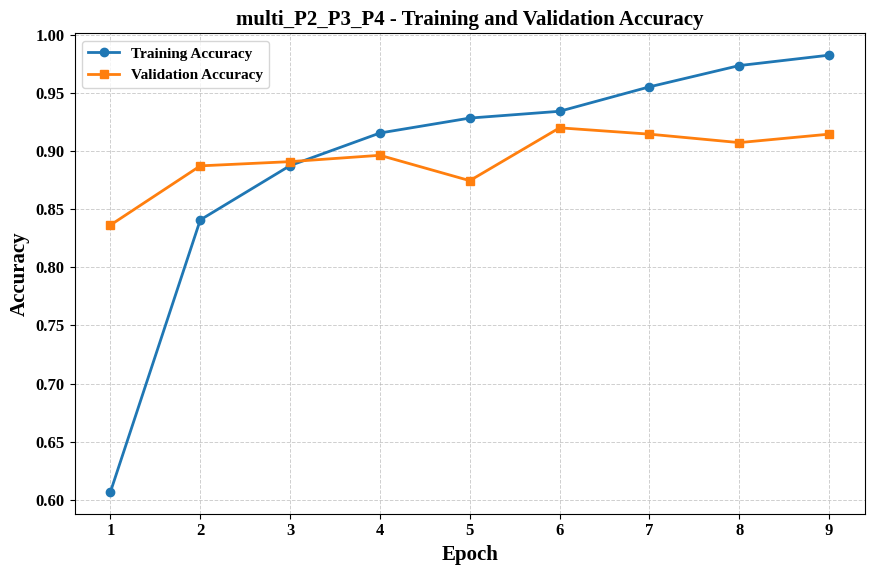

Saved: /content/resnet50_attention_results/plots/multi_P2_P3_P4_loss.png


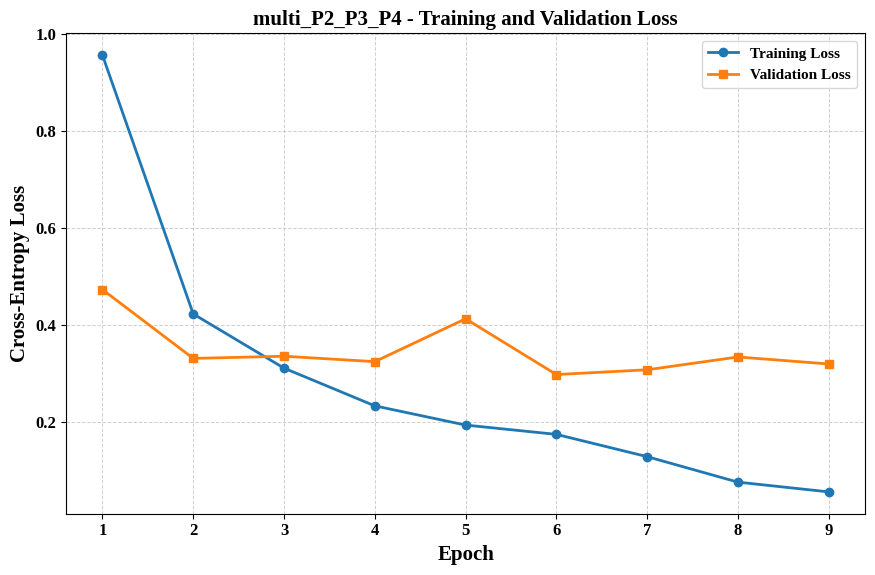


Experiment: multi_P2_P3_P4
Model: multi_P2_P3_P4
Accuracy: 0.8874773139745916
Precision: 0.8865113250860095
Recall: 0.8882034948482316
Macro_F1: 0.8850089222602359
Trainable_Parameters: 15655950
Total_Parameters: 24290190
Inference_ms_per_image: 9.513888593750153
Saved: /content/resnet50_attention_results/plots/multi_P2_P3_P4_confusion_matrix.png


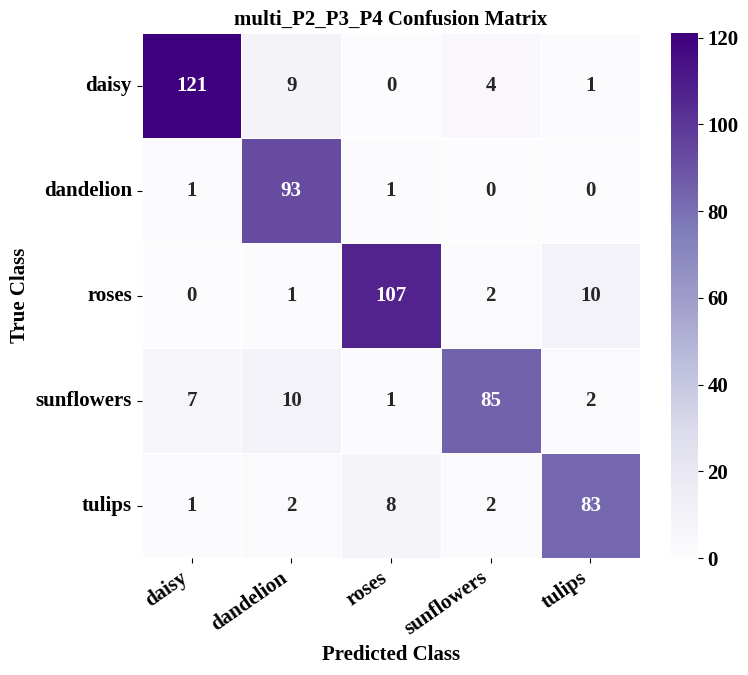

In [ ]:
# ============================================================
# EXPERIMENT 3: MULTI-STAGE ATTENTION
# ============================================================

multi_stage_results = {}

multi_stage_configurations = {
    # "P3_only": ["P3"],
    # "P4_only": ["P4"],
    "P3_P4": ["P3", "P4"],
    "P2_P3_P4": ["P2", "P3", "P4"]
}

RUN_MULTI_STAGE = True

if RUN_MULTI_STAGE:

    for experiment_name, selected_positions in (
        multi_stage_configurations.items()
    ):

        # Reuse the single-position P3 experiment.
        if selected_positions == ["P3"]:
            if "attention_type_results" in globals() and "channel_spatial_P3" in attention_type_results:
                experiment = attention_type_results[
                    "channel_spatial_P3"
                ]
            elif "position_results" in globals() and "P3" in position_results:
                experiment = position_results["P3"]
            else:
                experiment = run_experiment(
                    experiment_name="channel_spatial_P3",
                    attention_type="channel_spatial",
                    position="P3"
                )

        # Reuse the single-position P4 experiment.
        elif selected_positions == ["P4"]:
            if "position_results" in globals() and "P4" in position_results:
                experiment = position_results["P4"]
            else:
                experiment = run_experiment(
                    experiment_name="channel_spatial_P4",
                    attention_type="channel_spatial",
                    position="P4"
                )

        else:
            experiment = run_experiment(
                experiment_name=f"multi_{experiment_name}",
                attention_type="channel_spatial",
                position="P3",
                multi_positions=selected_positions
            )

        multi_stage_results[experiment_name] = experiment

In [ ]:
print(multi_stage_results)

{'P3_P4': {'model': <Functional name=resnet50_channel_spatial_P3, built=True>, 'history': {'accuracy': [0.50369793176651, 0.8555858135223389, 0.898404061794281, 0.9268198013305664, 0.9451148509979248, 0.9470611214637756, 0.9637991189956665, 0.9785909056663513], 'loss': [1.133915662765503, 0.3800222873687744, 0.2780297100543976, 0.2066611498594284, 0.1559959352016449, 0.1422395259141922, 0.10060432553291321, 0.06352745741605759], 'val_accuracy': [0.8309090733528137, 0.8799999952316284, 0.9018181562423706, 0.9090909361839294, 0.9036363363265991, 0.8963636159896851, 0.9090909361839294, 0.9200000166893005], 'val_loss': [0.49426817893981934, 0.37698251008987427, 0.3006897568702698, 0.2862092852592468, 0.3068724572658539, 0.36206239461898804, 0.33790573477745056, 0.3107041120529175], 'learning_rate': [0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 9.999999747378752e-06, 9.999999747378752e-06, 2.9999998787388904e-06]}, 'resul

In [ ]:
save_results(
    [
        multi_stage_results[k]["result"]
        for k in multi_stage_results
    ],
    filename="multi_stage_results.csv"
)

         Model  Accuracy  Precision   Recall  Macro_F1  Trainable_Parameters  Total_Parameters  Inference_ms_per_image
   multi_P3_P4  0.900181   0.903483 0.901729  0.898693              15622539          24256779                9.944365
multi_P2_P3_P4  0.887477   0.886511 0.888203  0.885009              15655950          24290190                9.513889


,Model,Accuracy,Precision,Recall,Macro_F1,Trainable_Parameters,Total_Parameters,Inference_ms_per_image
0,multi_P3_P4,0.900181,0.903483,0.901729,0.898693,15622539,24256779,9.944365
1,multi_P2_P3_P4,0.887477,0.886511,0.888203,0.885009,15655950,24290190,9.513889


In [ ]:
multi_stage_results1 = {
     "P3_only": {
        "result": {
            "Accuracy": 0.929220
        }
    },
    "P4_only": {
        "result": {
            "Accuracy": 0.925590
        }
    },
    "P3_P4": {
        "result": {
            "Accuracy": 0.900181
        }
    },
    "P2_P3_P4": {
        "result": {
            "Accuracy": 0.887477
        }
    }
}

Saved: /content/resnet50_attention_results/plots/multi_stage_attention_accuracy.png


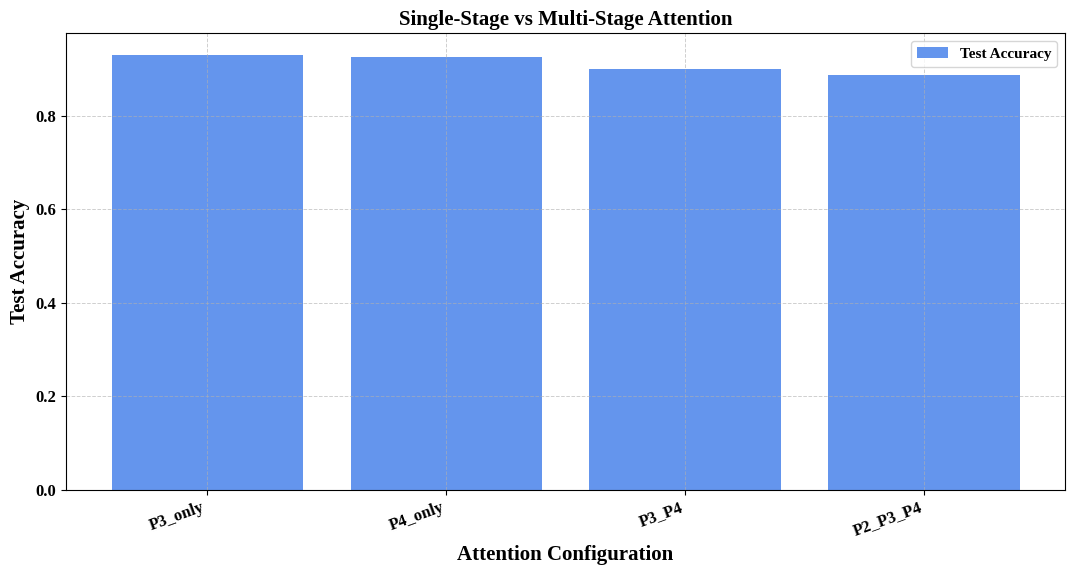

In [ ]:
# ============================================================
# MULTI-STAGE ACCURACY COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

names = list(multi_stage_results1.keys())

accuracies = [
    multi_stage_results1[name]["result"]["Accuracy"]
    for name in names
]

ax.bar(
    names,
    accuracies,
    color="cornflowerblue",
    label="Test Accuracy"
)

finish_plot(
    ax,
    "Single-Stage vs Multi-Stage Attention",
    "Attention Configuration",
    "Test Accuracy"
)

plt.xticks(rotation=20, ha="right")

fig.tight_layout()

save_plot(
    fig,
    "multi_stage_attention_accuracy.png"
)

plt.show()



Training: attention_order_channel_spatial
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 275ms/step - accuracy: 0.6676 - loss: 0.8376 - val_accuracy: 0.8727 - val_loss: 0.3398 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.8696 - loss: 0.3668 - val_accuracy: 0.9073 - val_loss: 0.2896 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.8933 - loss: 0.2994 - val_accuracy: 0.9018 - val_loss: 0.2756 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 197ms/step - accuracy: 0.9198 - loss: 0.2335 - val_accuracy: 0.8964 - val_loss: 0.2614 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.9241 - loss: 0.2125 - val_accuracy: 0.9145 - val_loss: 0.2428 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 278ms/step - accuracy: 0.9330 - loss: 0.1773 - val_accuracy: 

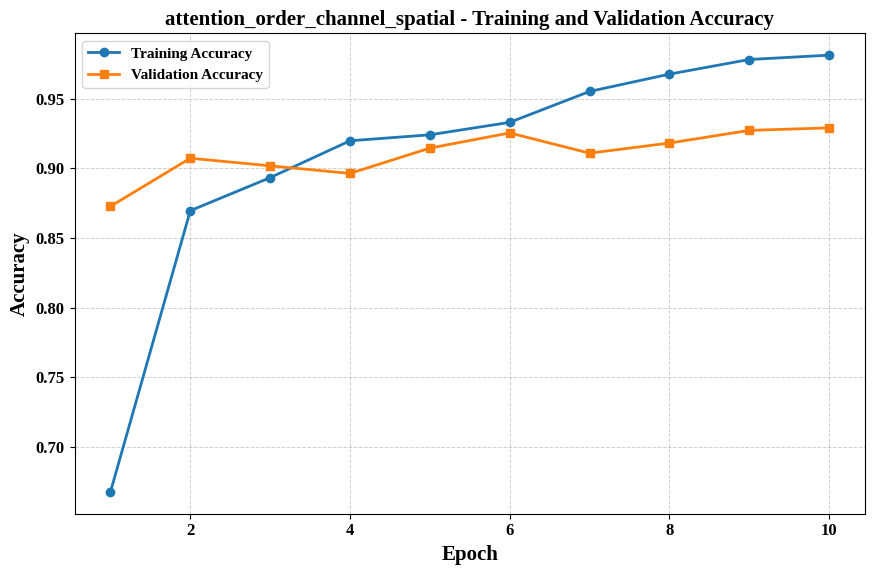

Saved: /content/resnet50_attention_results/plots/attention_order_channel_spatial_loss.png


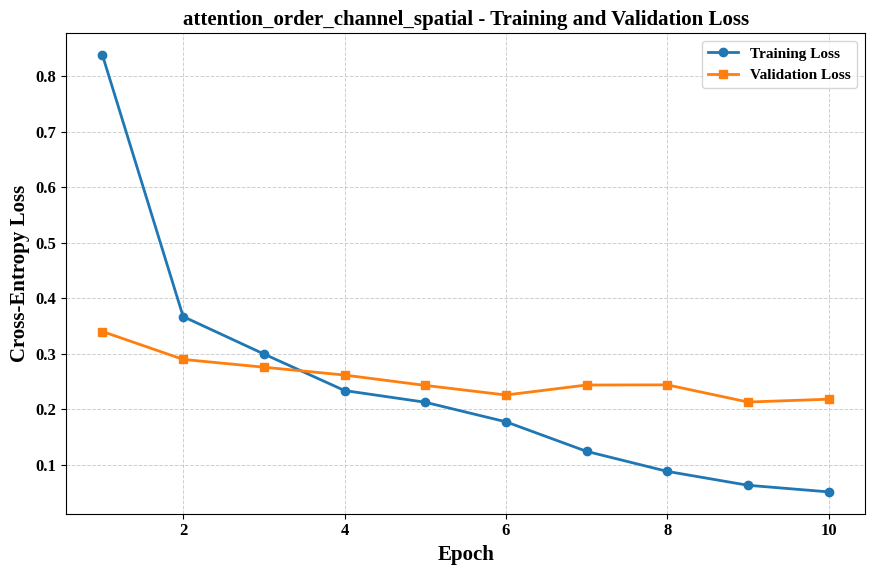


Experiment: attention_order_channel_spatial
Model: attention_order_channel_spatial
Accuracy: 0.9346642468239564
Precision: 0.9334033369530328
Recall: 0.9347887078808131
Macro_F1: 0.9336333046748193
Trainable_Parameters: 15095976
Total_Parameters: 23730216
Inference_ms_per_image: 9.800655321874766
Saved: /content/resnet50_attention_results/plots/attention_order_channel_spatial_confusion_matrix.png


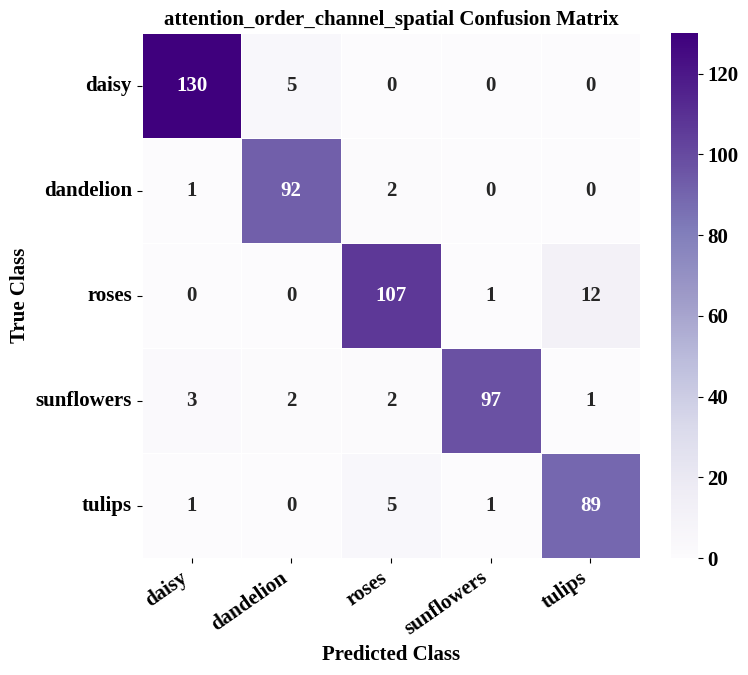


Training: attention_order_spatial_channel
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 263ms/step - accuracy: 0.7073 - loss: 0.7903 - val_accuracy: 0.8818 - val_loss: 0.3205 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 202ms/step - accuracy: 0.8762 - loss: 0.3490 - val_accuracy: 0.9109 - val_loss: 0.2692 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.8957 - loss: 0.2993 - val_accuracy: 0.9127 - val_loss: 0.2509 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.9132 - loss: 0.2385 - val_accuracy: 0.9200 - val_loss: 0.2334 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 196ms/step - accuracy: 0.9179 - loss: 0.2134 - val_accuracy: 0.9218 - val_loss: 0.2195 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Fine-tuning final ResNet50 stage...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 270ms/step - accuracy: 0.9420 - loss: 0.1725 - val_accuracy: 

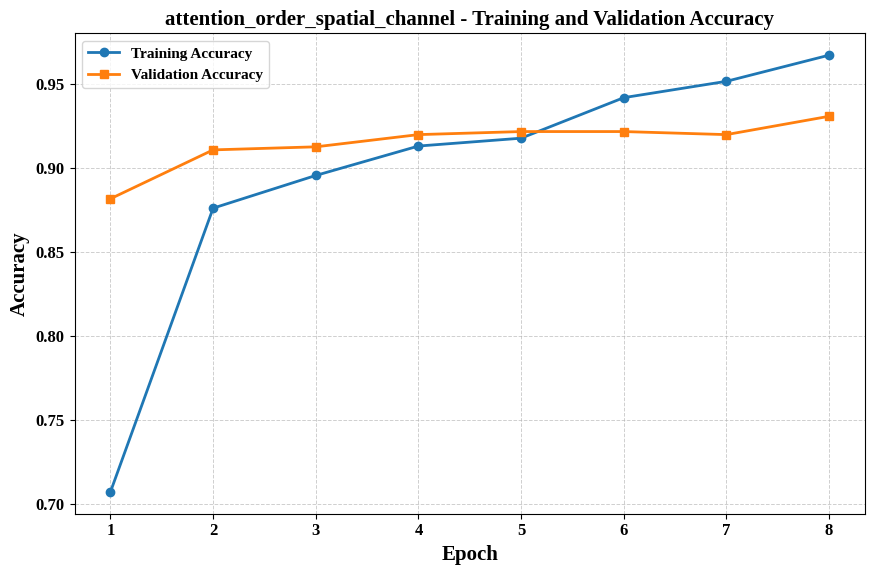

Saved: /content/resnet50_attention_results/plots/attention_order_spatial_channel_loss.png


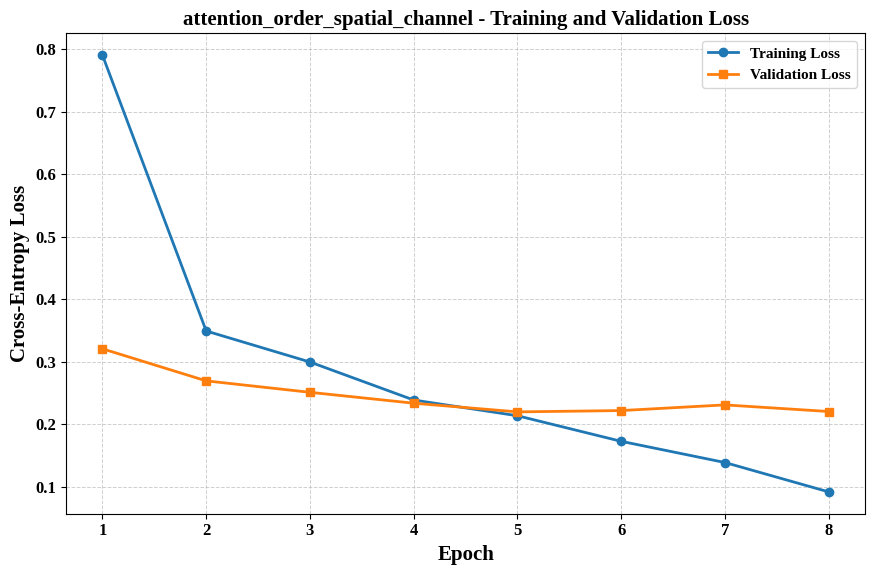


Experiment: attention_order_spatial_channel
Model: attention_order_spatial_channel
Accuracy: 0.9092558983666061
Precision: 0.9090858120077364
Recall: 0.9110783904204958
Macro_F1: 0.9086975161947036
Trainable_Parameters: 15095976
Total_Parameters: 23730216
Inference_ms_per_image: 9.766573648958381
Saved: /content/resnet50_attention_results/plots/attention_order_spatial_channel_confusion_matrix.png


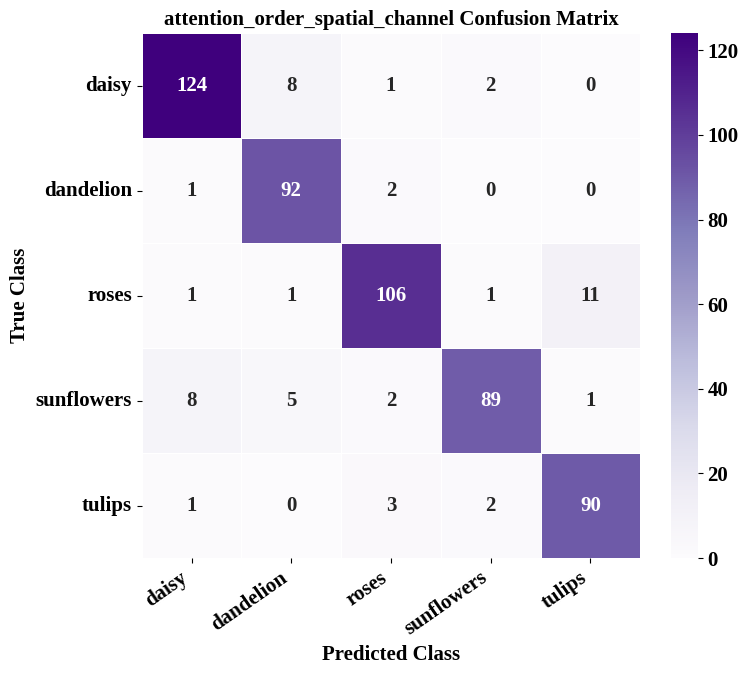

In [ ]:
# ============================================================
# EXPERIMENT 4: ATTENTION ORDER
# ============================================================

attention_order_results = {}

for order in [
    "channel_spatial",
    "spatial_channel"
]:

    experiment_name = f"attention_order_{order}"

    experiment = run_experiment(
        experiment_name=experiment_name,
        attention_type="channel_spatial",
        position="P3",
        attention_order=order
    )

    attention_order_results[order] = experiment

In [ ]:
save_results(
    [
        attention_order_results[k]["result"]
        for k in attention_order_results
    ],
    filename="attention_order_results.csv"
)

                          Model  Accuracy  Precision   Recall  Macro_F1  Trainable_Parameters  Total_Parameters  Inference_ms_per_image
attention_order_channel_spatial  0.934664   0.933403 0.934789  0.933633              15095976          23730216                9.800655
attention_order_spatial_channel  0.909256   0.909086 0.911078  0.908698              15095976          23730216                9.766574


,Model,Accuracy,Precision,Recall,Macro_F1,Trainable_Parameters,Total_Parameters,Inference_ms_per_image
0,attention_order_channel_spatial,0.934664,0.933403,0.934789,0.933633,15095976,23730216,9.800655
1,attention_order_spatial_channel,0.909256,0.909086,0.911078,0.908698,15095976,23730216,9.766574


Saved: /content/resnet50_attention_results/plots/attention_order_comparison.png


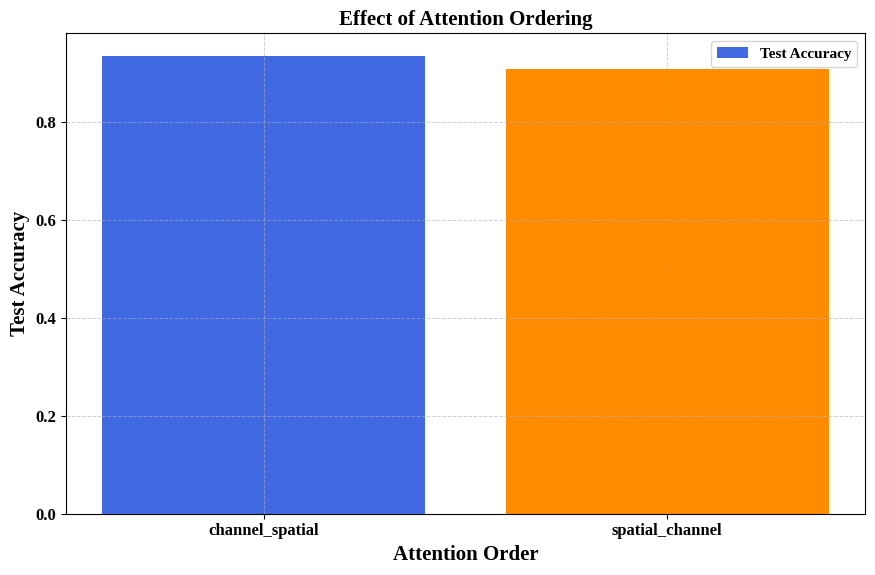

In [ ]:
# Plot the ordering comparison

# ============================================================
# ATTENTION ORDER COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

order_names = list(attention_order_results.keys())

order_accuracies = [
    attention_order_results[o]["result"]["Accuracy"]
    for o in order_names
]

ax.bar(
    order_names,
    order_accuracies,
    color=["royalblue", "darkorange"],
    label="Test Accuracy"
)

finish_plot(
    ax,
    "Effect of Attention Ordering",
    "Attention Order",
    "Test Accuracy"
)

fig.tight_layout()

save_plot(
    fig,
    "attention_order_comparison.png"
)

plt.show()


Training: spatial_kernel_3
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 239ms/step - accuracy: 0.7193 - loss: 0.7551 - val_accuracy: 0.8709 - val_loss: 0.3370 - learning_rate: 0.0010
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 193ms/step - accuracy: 0.8606 - loss: 0.4052 - val_accuracy: 0.9018 - val_loss: 0.2753 - learning_rate: 0.0010
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 200ms/step - accuracy: 0.8840 - loss: 0.3254 - val_accuracy: 0.9018 - val_loss: 0.2678 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Fine-tuning final ResNet50 stage...
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 273ms/step - accuracy: 0.9179 - loss: 0.2399 - val_accuracy: 0.9200 - val_loss: 0.2275 - learning_rate: 1.0000e-05
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 259ms/step - accuracy: 0.9342 - loss: 0.1841 - val_accuracy: 0.9182 - val_loss: 0.2113 - learning_rate: 1.0000e-05
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 219ms/step - accuracy: 0.9560 - loss: 0.1207 - val_accuracy: 0.9127 

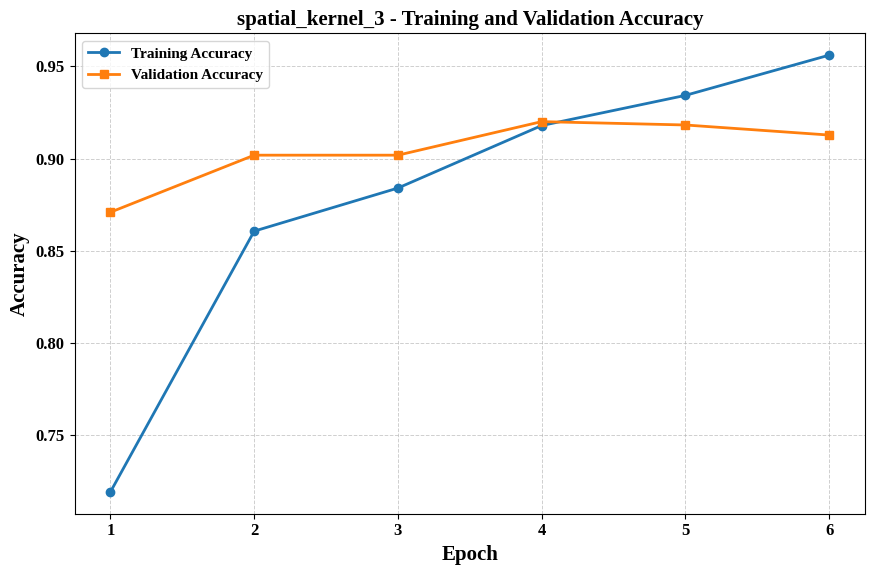

Saved: /content/resnet50_attention_results/plots/spatial_kernel_3_loss.png


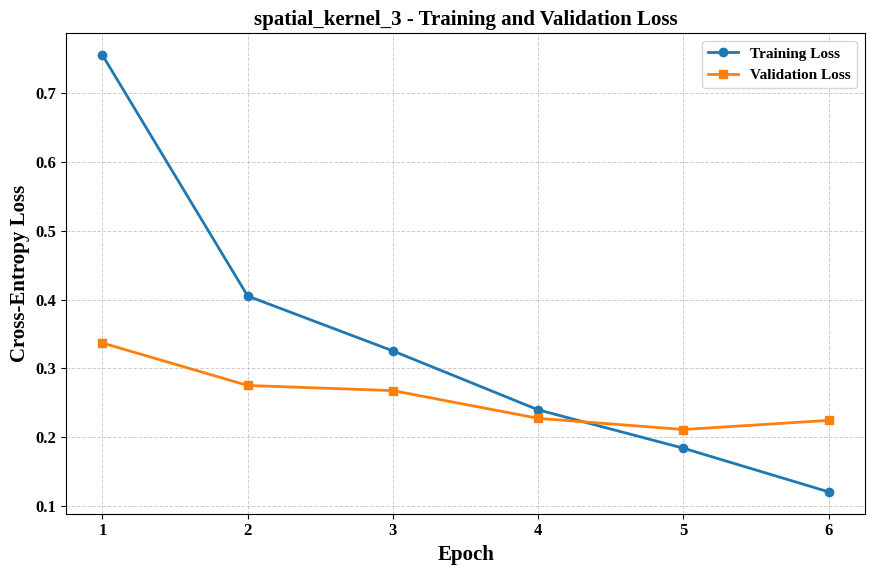


Experiment: spatial_kernel_3
Model: spatial_kernel_3
Accuracy: 0.9201451905626135
Precision: 0.919217480051714
Recall: 0.9199495265942634
Macro_F1: 0.9185731934238616
Trainable_Parameters: 14963736
Total_Parameters: 23597976
Inference_ms_per_image: 9.194100454166687
Saved: /content/resnet50_attention_results/plots/spatial_kernel_3_confusion_matrix.png


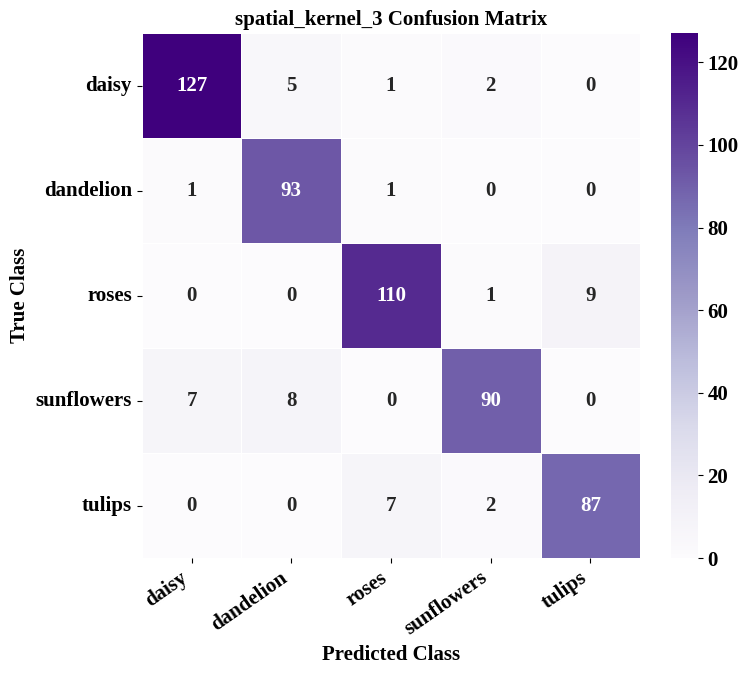


Training: spatial_kernel_5
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 244ms/step - accuracy: 0.7116 - loss: 0.7904 - val_accuracy: 0.8709 - val_loss: 0.3658 - learning_rate: 0.0010
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.8653 - loss: 0.4018 - val_accuracy: 0.8982 - val_loss: 0.2951 - learning_rate: 0.0010
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 197ms/step - accuracy: 0.8813 - loss: 0.3300 - val_accuracy: 0.9164 - val_loss: 0.2676 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 3.
Fine-tuning final ResNet50 stage...
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 269ms/step - accuracy: 0.9128 - loss: 0.2341 - val_accuracy: 0.9218 - val_loss: 0.2239 - learning_rate: 1.0000e-05
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 226ms/step - accuracy: 0.9366 - loss: 0.1739 - val_accuracy: 0.9127 - val_loss: 0.2272 - learning_rate: 1.0000e-05
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.9589 - loss: 0.1156
Epoch 3: ReduceLROnPlate

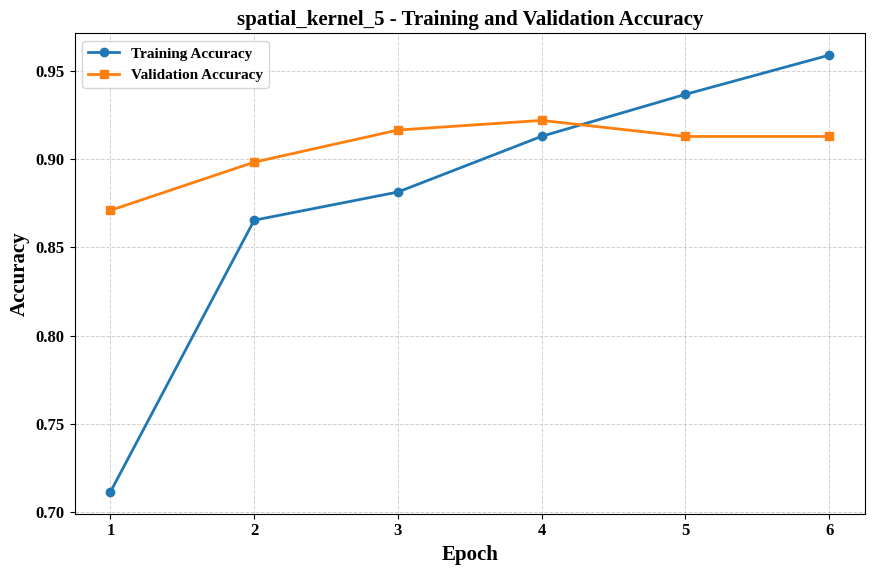

Saved: /content/resnet50_attention_results/plots/spatial_kernel_5_loss.png


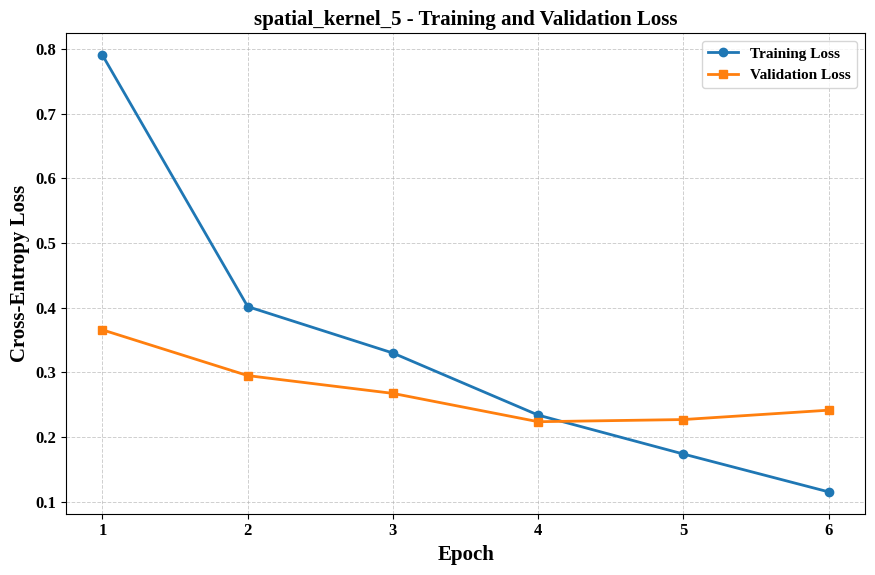


Experiment: spatial_kernel_5
Model: spatial_kernel_5
Accuracy: 0.9038112522686026
Precision: 0.9023414181879765
Recall: 0.9047093428014481
Macro_F1: 0.9026077892435204
Trainable_Parameters: 14963768
Total_Parameters: 23598008
Inference_ms_per_image: 9.376348875000081
Saved: /content/resnet50_attention_results/plots/spatial_kernel_5_confusion_matrix.png


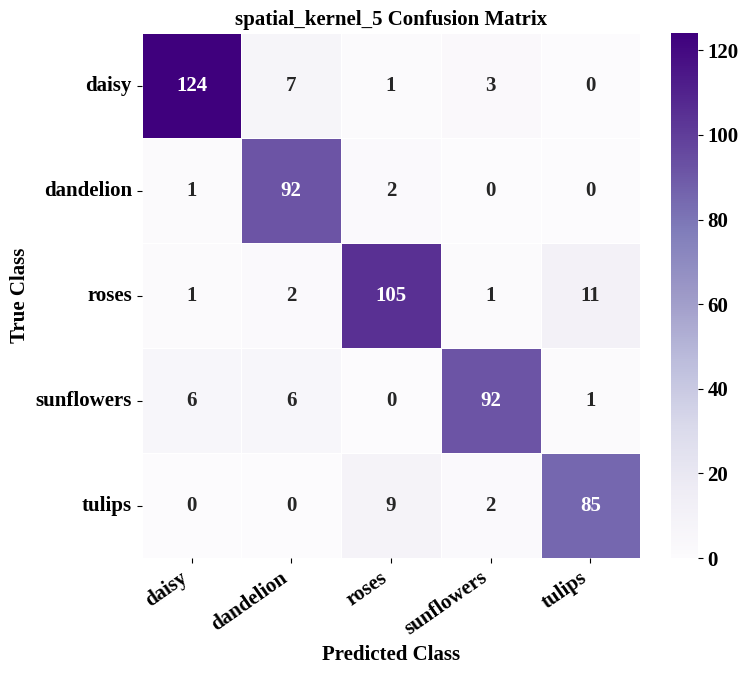


Training: spatial_kernel_7
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 245ms/step - accuracy: 0.6668 - loss: 0.8427 - val_accuracy: 0.8727 - val_loss: 0.3338 - learning_rate: 0.0010
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 201ms/step - accuracy: 0.8571 - loss: 0.3949 - val_accuracy: 0.9000 - val_loss: 0.2631 - learning_rate: 0.0010
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.8856 - loss: 0.3172 - val_accuracy: 0.9073 - val_loss: 0.2632 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.
Fine-tuning final ResNet50 stage...
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 297ms/step - accuracy: 0.9023 - loss: 0.2695 - val_accuracy: 0.9091 - val_loss: 0.2219 - learning_rate: 1.0000e-05
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 231ms/step - accuracy: 0.9272 - loss: 0.2058 - val_accuracy: 0.9091 - val_loss: 0.2141 - learning_rate: 1.0000e-05
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 227ms/step - accuracy: 0.9521 - loss: 0.1393 - val_accuracy: 0.9145 

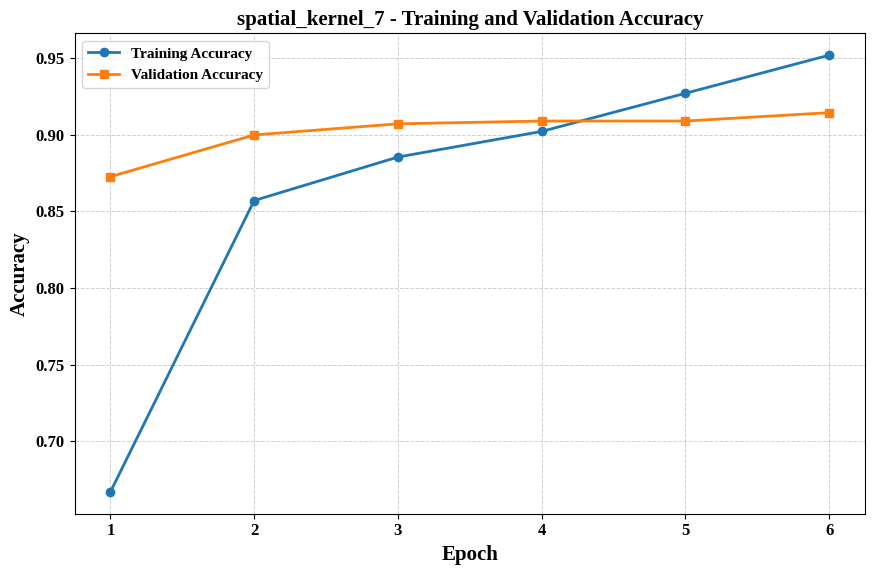

Saved: /content/resnet50_attention_results/plots/spatial_kernel_7_loss.png


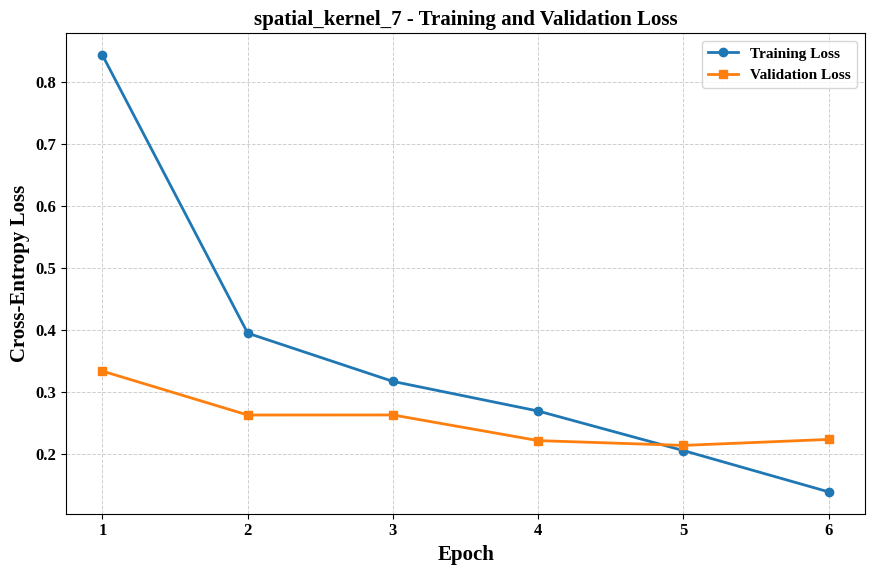


Experiment: spatial_kernel_7
Model: spatial_kernel_7
Accuracy: 0.9183303085299456
Precision: 0.9167155745018339
Recall: 0.9205270119743805
Macro_F1: 0.9171736689622781
Trainable_Parameters: 14963816
Total_Parameters: 23598056
Inference_ms_per_image: 10.171732312500009
Saved: /content/resnet50_attention_results/plots/spatial_kernel_7_confusion_matrix.png


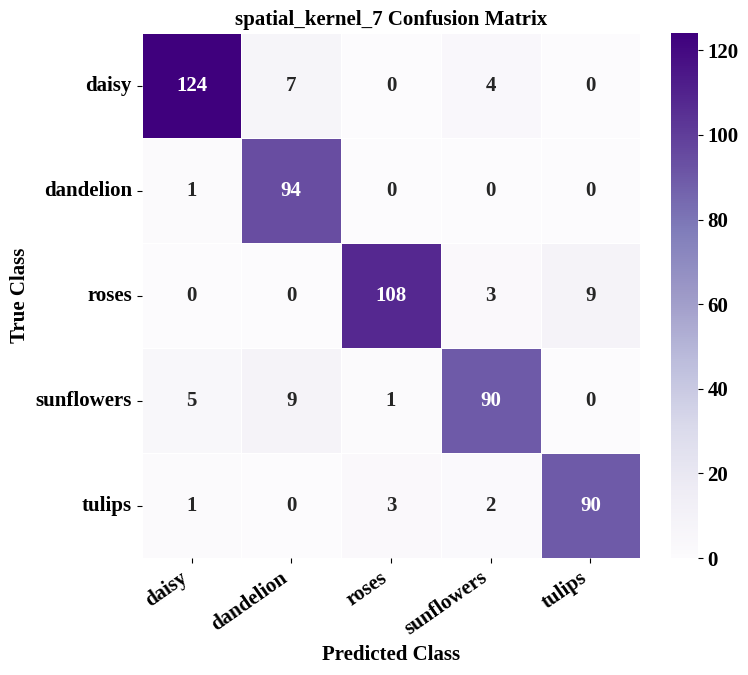

In [ ]:
# ============================================================
# EXPERIMENT 5: SPATIAL KERNEL SIZE
# ============================================================

kernel_results = {}

for kernel_size in [3, 5, 7]:

    experiment_name = f"spatial_kernel_{kernel_size}"

    experiment = run_experiment(
        experiment_name=experiment_name,
        attention_type="spatial",
        position="P3",
        kernel_size=kernel_size
    )

    kernel_results[kernel_size] = experiment

In [ ]:
save_results(
    [
        kernel_results[k]["result"]
        for k in kernel_results
    ],
    filename="spatial_kernel_results.csv"
)

           Model  Accuracy  Precision   Recall  Macro_F1  Trainable_Parameters  Total_Parameters  Inference_ms_per_image
spatial_kernel_3  0.920145   0.919217 0.919950  0.918573              14963736          23597976                9.194100
spatial_kernel_5  0.903811   0.902341 0.904709  0.902608              14963768          23598008                9.376349
spatial_kernel_7  0.918330   0.916716 0.920527  0.917174              14963816          23598056               10.171732


,Model,Accuracy,Precision,Recall,Macro_F1,Trainable_Parameters,Total_Parameters,Inference_ms_per_image
0,spatial_kernel_3,0.920145,0.919217,0.919950,0.918573,14963736,23597976,9.194100
1,spatial_kernel_5,0.903811,0.902341,0.904709,0.902608,14963768,23598008,9.376349
2,spatial_kernel_7,0.918330,0.916716,0.920527,0.917174,14963816,23598056,10.171732


Saved: /content/resnet50_attention_results/plots/spatial_kernel_accuracy.png


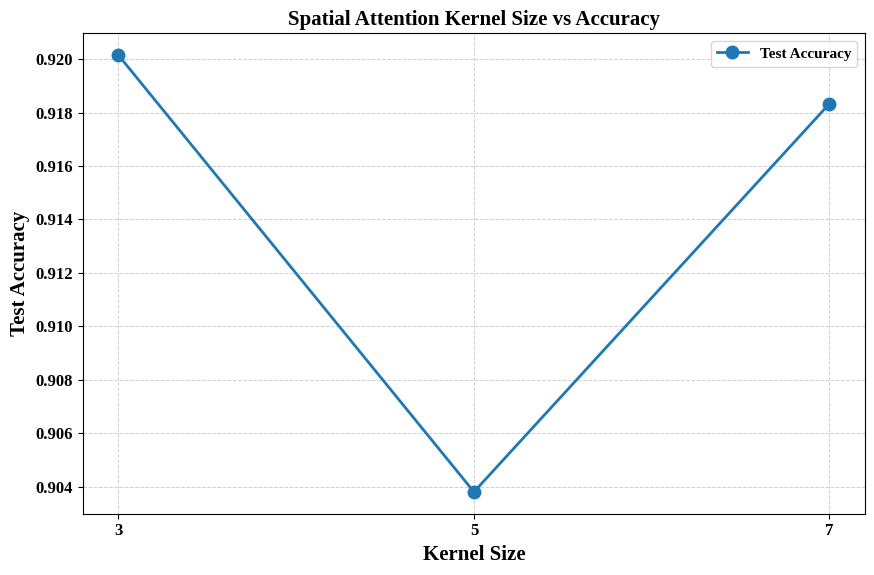

In [ ]:
# ============================================================
# KERNEL SIZE VS ACCURACY
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

kernel_sizes = list(kernel_results.keys())

kernel_accuracies = [
    kernel_results[k]["result"]["Accuracy"]
    for k in kernel_sizes
]

ax.plot(
    kernel_sizes,
    kernel_accuracies,
    marker="o",
    markersize=9,
    linewidth=2,
    label="Test Accuracy"
)

finish_plot(
    ax,
    "Spatial Attention Kernel Size vs Accuracy",
    "Kernel Size",
    "Test Accuracy"
)

ax.set_xticks([3, 5, 7])

fig.tight_layout()

save_plot(
    fig,
    "spatial_kernel_accuracy.png"
)

plt.show()

Saved: /content/resnet50_attention_results/plots/spatial_kernel_inference_time.png


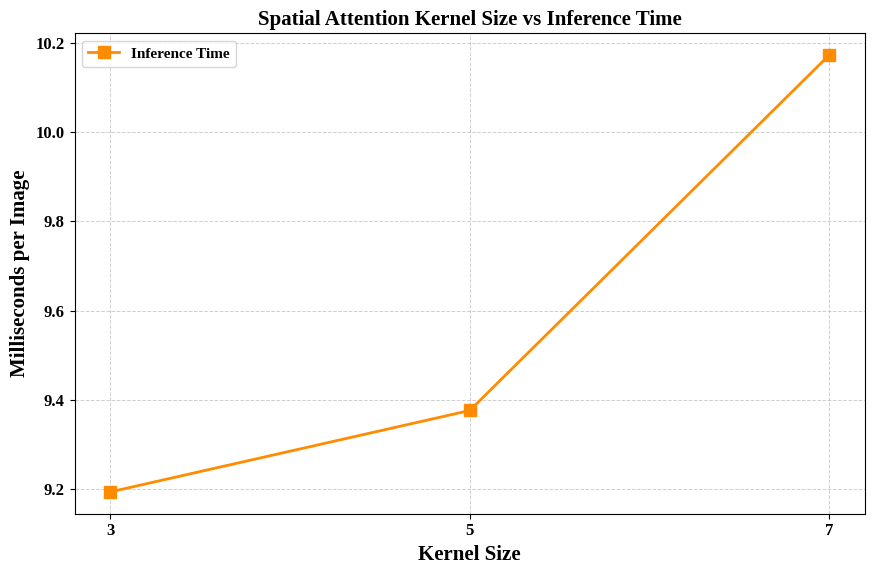

In [ ]:
# ============================================================
# KERNEL SIZE VS INFERENCE TIME
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

kernel_times = [
    kernel_results[k]["result"]["Inference_ms_per_image"]
    for k in kernel_sizes
]

ax.plot(
    kernel_sizes,
    kernel_times,
    marker="s",
    markersize=9,
    linewidth=2,
    color="darkorange",
    label="Inference Time"
)

finish_plot(
    ax,
    "Spatial Attention Kernel Size vs Inference Time",
    "Kernel Size",
    "Milliseconds per Image"
)

ax.set_xticks([3, 5, 7])

fig.tight_layout()

save_plot(
    fig,
    "spatial_kernel_inference_time.png"
)

plt.show()

NameError: name 'results_df' is not defined

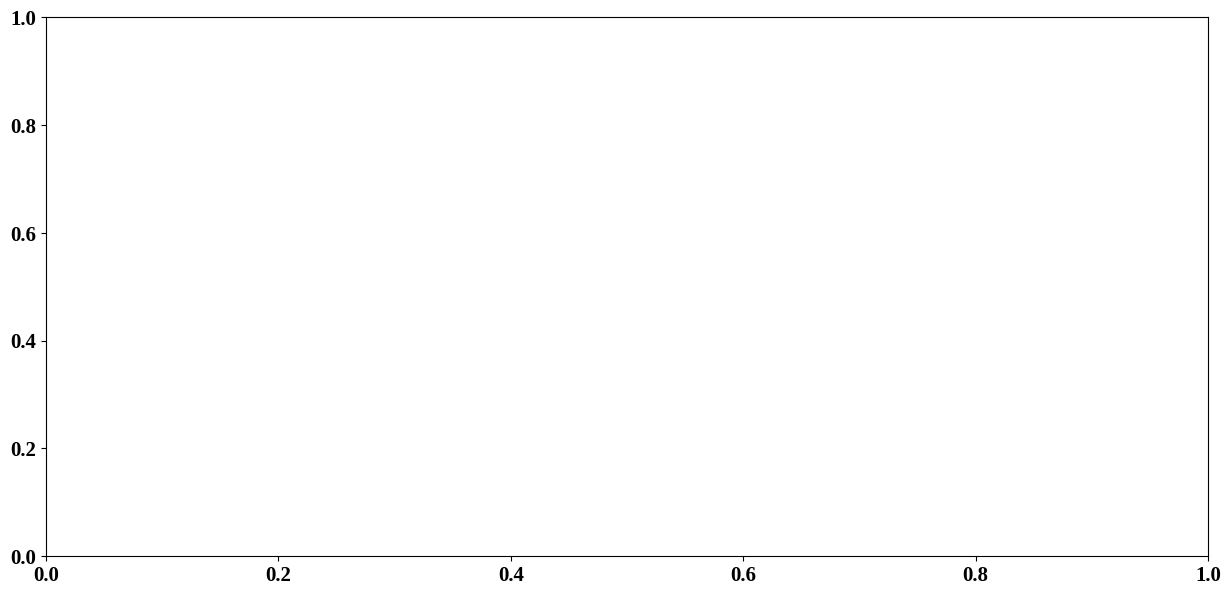

In [ ]:
# ============================================================
# ACCURACY COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(15, 7))

plot_data = (
    results_df
    .drop_duplicates(subset=["Model"])
    .sort_values("Accuracy", ascending=False)
)

ax.bar(
    plot_data["Model"],
    plot_data["Accuracy"],
    color="steelblue",
    label="Test Accuracy"
)

finish_plot(
    ax,
    "Attention Mechanism vs Classification Accuracy",
    "Model",
    "Test Accuracy"
)

plt.xticks(rotation=60, ha="right")

fig.tight_layout()

save_plot(
    fig,
    "all_models_accuracy.png"
)

plt.show()


In [ ]:
# ============================================================
# MACRO F1 COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(15, 7))

plot_data = (
    results_df
    .drop_duplicates(subset=["Model"])
    .sort_values("Macro_F1", ascending=False)
)

ax.bar(
    plot_data["Model"],
    plot_data["Macro_F1"],
    color="seagreen",
    label="Macro F1"
)

finish_plot(
    ax,
    "Attention Mechanism vs Macro F1-score",
    "Model",
    "Macro F1-score"
)

plt.xticks(rotation=60, ha="right")

fig.tight_layout()

save_plot(
    fig,
    "all_models_macro_f1.png"
)

plt.show()

In [ ]:
# ============================================================
# ACCURACY VS PARAMETERS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

plot_data = results_df.drop_duplicates(
    subset=["Model"]
)

ax.scatter(
    plot_data["Total_Parameters"] / 1e6,
    plot_data["Accuracy"],
    s=100,
    alpha=0.8,
    label="Models"
)

# Label each point.
for _, row in plot_data.iterrows():

    ax.annotate(
        row["Model"],
        (
            row["Total_Parameters"] / 1e6,
            row["Accuracy"]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

finish_plot(
    ax,
    "Accuracy vs Model Complexity",
    "Total Parameters (Millions)",
    "Test Accuracy"
)

fig.tight_layout()

save_plot(
    fig,
    "accuracy_vs_parameters.png"
)

plt.show()



In [ ]:
# ============================================================
# MACRO F1 VS INFERENCE TIME
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

plot_data = results_df.drop_duplicates(
    subset=["Model"]
)

ax.scatter(
    plot_data["Inference_ms_per_image"],
    plot_data["Macro_F1"],
    s=100,
    alpha=0.8,
    color="darkorange",
    label="Models"
)

for _, row in plot_data.iterrows():

    ax.annotate(
        row["Model"],
        (
            row["Inference_ms_per_image"],
            row["Macro_F1"]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

finish_plot(
    ax,
    "Macro F1 vs Inference Time",
    "Inference Time (ms/Image)",
    "Macro F1-score"
)

fig.tight_layout()

save_plot(
    fig,
    "macro_f1_vs_inference_time.png"
)

plt.show()

In [ ]:
# ============================================================
# PRECISION, RECALL, F1 COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(15, 7))

plot_data = results_df.drop_duplicates(
    subset=["Model"]
)

x = np.arange(len(plot_data))
width = 0.25

ax.bar(
    x - width,
    plot_data["Precision"],
    width,
    label="Macro Precision"
)

ax.bar(
    x,
    plot_data["Recall"],
    width,
    label="Macro Recall"
)

ax.bar(
    x + width,
    plot_data["Macro_F1"],
    width,
    label="Macro F1"
)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["Model"],
    rotation=60,
    ha="right"
)

finish_plot(
    ax,
    "Precision, Recall and Macro F1 Comparison",
    "Model",
    "Score"
)

fig.tight_layout()

save_plot(
    fig,
    "precision_recall_f1_comparison.png"
)

plt.show()

Saved: /content/resnet50_attention_results/plots/sample_test_image.png


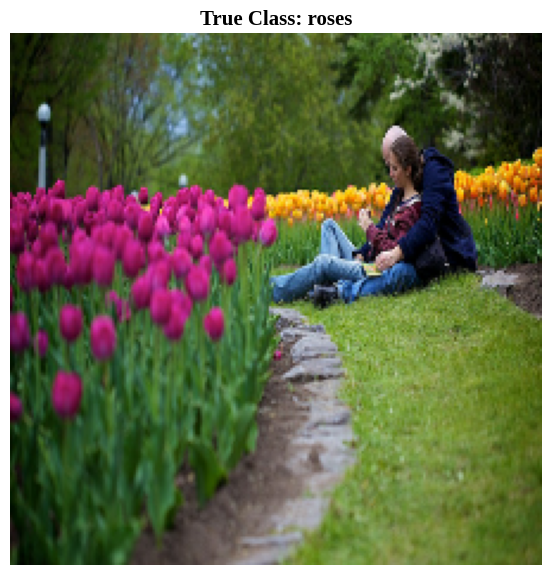

In [ ]:
# ============================================================
# SELECT A TEST IMAGE
# ============================================================

def display_input_image(index=0):

    image = X_test_raw[index] / 255.0

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.imshow(np.clip(image, 0, 1))

    ax.set_title(
        f"True Class: {CLASS_NAMES[y_test[index]]}",
        fontweight="bold"
    )

    ax.axis("off")

    fig.tight_layout()

    save_plot(
        fig,
        "sample_test_image.png"
    )

    plt.show()


display_input_image(0)

In [ ]:
# ============================================================
# CHANNEL ATTENTION VISUALIZATION
# ============================================================

def plot_channel_weights(
    model,
    image_index=0,
    layer_name="P3_channel_fc2",
    top_k=20,
    filename="channel_attention_weights.png"
):

    try:

        target_layer = model.get_layer(layer_name)

        probe = Model(
            inputs=model.input,
            outputs=target_layer.output
        )

        weights = probe.predict(
            X_test[image_index:image_index + 1],
            verbose=0
        ).reshape(-1)

        top_indices = np.argsort(weights)[-top_k:][::-1]

        fig, ax = plt.subplots(figsize=(12, 6))

        ax.bar(
            np.arange(len(top_indices)),
            weights[top_indices],
            color="steelblue",
            label="Channel Weight"
        )

        ax.set_xticks(
            np.arange(len(top_indices))
        )

        ax.set_xticklabels(
            top_indices,
            rotation=45
        )

        finish_plot(
            ax,
            "Top Channel-Attention Weights",
            "Channel Index",
            "Attention Weight"
        )

        fig.tight_layout()

        save_plot(fig, filename)

        plt.show()

    except ValueError as error:

        print(
            "Could not access the requested channel layer:",
            layer_name
        )

        print("Check model.get_layer_names() or the model summary.")
        print(error)

# Run the function on a trained channel-attention model:

channel_model = attention_type_results["channel_P3"]["model"]

plot_channel_weights(
    channel_model,
    image_index=0,
    layer_name="P3_channel_fc2",
    filename="channel_attention_weights.png"
)

NameError: name 'attention_type_results' is not defined

In [ ]:
# ============================================================
# SPATIAL ATTENTION MAP
# ============================================================

def plot_spatial_attention(
    model,
    image_index=0,
    layer_name="P3_spatial_conv",
    filename="spatial_attention_map.png"
):

    target_layer = model.get_layer(layer_name)

    probe = Model(
        inputs=model.input,
        outputs=target_layer.output
    )

    attention_map = probe.predict(
        X_test[image_index:image_index + 1],
        verbose=0
    )[0, :, :, 0]

    image = X_test_raw[image_index] / 255.0

    # Resize attention map to original image dimensions.
    attention_resized = tf.image.resize(
        attention_map[..., np.newaxis],
        (IMAGE_SIZE, IMAGE_SIZE)
    ).numpy().squeeze()

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5)
    )

    axes[0].imshow(
        np.clip(image, 0, 1)
    )

    axes[0].set_title("Input Image")

    axes[1].imshow(
        attention_resized,
        cmap="jet"
    )

    axes[1].set_title("Spatial Attention Map")

    axes[2].imshow(
        np.clip(image, 0, 1)
    )

    axes[2].imshow(
        attention_resized,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title("Attention Overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        "Spatial Attention Visualization",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

    return attention_resized

In [ ]:
spatial_model = attention_type_results["spatial_P3"]["model"]

attention_map = plot_spatial_attention(
    spatial_model,
    image_index=0,
    layer_name="P3_spatial_conv",
    filename="spatial_attention_overlay.png"
)

NameError: name 'attention_type_results' is not defined

In [ ]:
cs_model = attention_type_results["channel_spatial_P3"]["model"]

attention_map_cs = plot_spatial_attention(
    cs_model,
    image_index=0,
    layer_name="P3_cs_spatial_conv",
    filename="channel_spatial_attention_overlay.png"
)

NameError: name 'attention_type_results' is not defined

In [ ]:
# ============================================================
# FEATURE MAP VISUALIZATION
# ============================================================

def plot_feature_maps(
    model,
    image_index=0,
    before_layer="P3_cs_spatial_concat",
    after_layer="P3_cs_spatial_multiply",
    max_channels=8,
    filename="feature_maps_before_after.png"
):

    before_model = Model(
        inputs=model.input,
        outputs=model.get_layer(before_layer).output
    )

    after_model = Model(
        inputs=model.input,
        outputs=model.get_layer(after_layer).output
    )

    before = before_model.predict(
        X_test[image_index:image_index + 1],
        verbose=0
    )[0]

    after = after_model.predict(
        X_test[image_index:image_index + 1],
        verbose=0
    )[0]

    channels = min(
        max_channels,
        before.shape[-1],
        after.shape[-1]
    )

    fig, axes = plt.subplots(
        2,
        channels,
        figsize=(2.5 * channels, 6)
    )

    for i in range(channels):

        axes[0, i].imshow(
            before[:, :, i],
            cmap="viridis"
        )

        axes[0, i].set_title(
            f"Before {i}"
        )

        axes[1, i].imshow(
            after[:, :, i],
            cmap="viridis"
        )

        axes[1, i].set_title(
            f"After {i}"
        )

        axes[0, i].axis("off")
        axes[1, i].axis("off")

    fig.suptitle(
        "Feature Maps Before and After Attention",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

plot_feature_maps(
    cs_model,
    image_index=0,
    filename="feature_maps_before_after.png"
)

NameError: name 'cs_model' is not defined

In [ ]:
# ============================================================
# ATTENTION MAPS AT DIFFERENT POSITIONS
# ============================================================

def compare_attention_positions(
    image_index=0,
    filename="attention_positions_comparison.png"
):

    models_to_compare = {
        "P2": position_results["P2"]["model"],
        "P3": position_results["P3"]["model"],
        "P4": position_results["P4"]["model"]
    }

    layer_names = {
        "P2": "P2_cs_spatial_conv",
        "P3": "P3_cs_spatial_conv",
        "P4": "P4_cs_spatial_conv"
    }

    image = X_test_raw[image_index] / 255.0

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(18, 5)
    )

    axes[0].imshow(
        np.clip(image, 0, 1)
    )

    axes[0].set_title("Input Image")
    axes[0].axis("off")

    for i, position in enumerate(
        ["P2", "P3", "P4"],
        start=1
    ):

        model = models_to_compare[position]

        probe = Model(
            inputs=model.input,
            outputs=model.get_layer(
                layer_names[position]
            ).output
        )

        amap = probe.predict(
            X_test[image_index:image_index + 1],
            verbose=0
        )[0, :, :, 0]

        amap = tf.image.resize(
            amap[..., np.newaxis],
            (IMAGE_SIZE, IMAGE_SIZE)
        ).numpy().squeeze()

        axes[i].imshow(
            np.clip(image, 0, 1)
        )

        axes[i].imshow(
            amap,
            cmap="jet",
            alpha=0.5
        )

        axes[i].set_title(
            f"Attention at {position}"
        )

        axes[i].axis("off")

    fig.suptitle(
        "Spatial Attention at Different ResNet50 Stages",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

Run:

compare_attention_positions(
    image_index=0
)

SyntaxError: invalid syntax (195774215.py, line 91)

In [ ]:
# ============================================================
# GRAD-CAM
# ============================================================

def find_last_feature_model(model):
    """
    Find the last nested feature-extractor model with
    a four-dimensional output tensor.
    """

    candidates = []

    for layer in model.layers:

        if isinstance(layer, tf.keras.Model):

            try:

                output_shape = layer.output.shape

                if len(output_shape) == 4:
                    candidates.append(layer)

            except Exception:
                pass

    if not candidates:
        raise ValueError(
            "No suitable nested feature model was found."
        )

    return candidates[-1]


def generate_gradcam(
    model,
    image_index,
    class_index=None
):

    # Locate a feature-extractor output.
    feature_model = find_last_feature_model(model)

    grad_model = Model(
        inputs=model.inputs,
        outputs=[
            feature_model.output,
            model.output
        ]
    )

    image = X_test[image_index:image_index + 1]

    with tf.GradientTape() as tape:

        feature_maps, predictions = grad_model(
            image,
            training=False
        )

        if class_index is None:
            class_index = int(
                tf.argmax(
                    predictions[0]
                ).numpy()
            )

        class_score = predictions[:, class_index]

    gradients = tape.gradient(
        class_score,
        feature_maps
    )

    # Global-average-pool the gradients.
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Weighted sum of feature maps.
    cam = tf.reduce_sum(
        feature_maps * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    # Keep positive contributions.
    cam = tf.nn.relu(cam)

    cam = cam[0].numpy()

    # Normalize.
    cam = cam / (
        np.max(cam) + 1e-8
    )

    # Resize to input dimensions.
    cam = tf.image.resize(
        cam[..., np.newaxis],
        (IMAGE_SIZE, IMAGE_SIZE)
    ).numpy().squeeze()

    return cam, class_index

In [ ]:
# ============================================================
# DISPLAY GRAD-CAM
# ============================================================

def plot_gradcam(
    model,
    image_index=0,
    title="Grad-CAM",
    filename="gradcam.png"
):

    cam, predicted_class = generate_gradcam(
        model,
        image_index
    )

    image = X_test_raw[image_index] / 255.0

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(
        np.clip(image, 0, 1)
    )

    axes[0].set_title(
        f"True: {CLASS_NAMES[y_test[image_index]]}"
    )

    axes[1].imshow(
        cam,
        cmap="jet"
    )

    axes[1].set_title(
        "Grad-CAM Map"
    )

    axes[2].imshow(
        np.clip(image, 0, 1)
    )

    axes[2].imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title(
        f"Predicted: {CLASS_NAMES[predicted_class]}"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        title,
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

    return cam

In [ ]:
baseline_cam = plot_gradcam(
    baseline_model,
    image_index=0,
    title="Baseline ResNet50 Grad-CAM",
    filename="baseline_gradcam.png"
)

In [ ]:
attention_model = attention_type_results[
    "channel_spatial_P3"
]["model"]

attention_cam = plot_gradcam(
    attention_model,
    image_index=0,
    title="Channel-Spatial Attention ResNet50 Grad-CAM",
    filename="channel_spatial_gradcam.png"
)

In [ ]:
# ============================================================
# GRAD-CAM COMPARISON
# ============================================================

def compare_gradcam(
    image_index=0,
    filename="baseline_vs_attention_gradcam.png"
):

    baseline_cam, baseline_class = generate_gradcam(
        baseline_model,
        image_index
    )

    attention_cam, attention_class = generate_gradcam(
        attention_model,
        image_index
    )

    image = X_test_raw[image_index] / 255.0

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 5)
    )

    axes[0].imshow(
        np.clip(image, 0, 1)
    )

    axes[0].set_title("Input")

    axes[1].imshow(
        np.clip(image, 0, 1)
    )

    axes[1].imshow(
        baseline_cam,
        cmap="jet",
        alpha=0.45
    )

    axes[1].set_title(
        f"Baseline: {CLASS_NAMES[baseline_class]}"
    )

    axes[2].imshow(
        np.clip(image, 0, 1)
    )

    axes[2].imshow(
        attention_cam,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title(
        f"Attention: {CLASS_NAMES[attention_class]}"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        "Baseline vs Attention Model Grad-CAM",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

compare_gradcam(image_index=0)

In [ ]:
# ============================================================
# CORRECT AND INCORRECT PREDICTIONS
# ============================================================

def find_correct_incorrect(
    model,
    number_correct=3,
    number_incorrect=2
):

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    correct = np.where(
        predictions == y_test
    )[0]

    incorrect = np.where(
        predictions != y_test
    )[0]

    return (
        correct[:number_correct],
        incorrect[:number_incorrect]
    )


correct_indices, incorrect_indices = find_correct_incorrect(
    attention_model
)

print("Correctly classified test images:", correct_indices)
print("Incorrectly classified test images:", incorrect_indices)

# ============================================================
# GRAD-CAM FOR SELECTED TEST IMAGES
# ============================================================

selected_indices = list(correct_indices) + list(incorrect_indices)

for idx in selected_indices:

    plot_gradcam(
        attention_model,
        image_index=int(idx),
        title=f"Grad-CAM for Test Image {idx}",
        filename=f"gradcam_test_image_{idx}.png"
    )

In [ ]:
# Add this line inside SelfAttention2D.call(),
# immediately after the softmax operation:

self.last_attention = attention
attention = tf.nn.softmax(
    attention,
    axis=-1
)

# Store the attention matrix for visualization.
self.last_attention = attention
output = tf.matmul(attention, v)

In [ ]:
# ============================================================
# SELF-ATTENTION RESPONSE
# ============================================================

def plot_self_attention_response(
    model,
    image_index=0,
    layer_name="P3_self_attention",
    filename="self_attention_response.png"
):

    image_batch = X_test[
        image_index:image_index + 1
    ]

    # Run one forward pass.
    _ = model(
        image_batch,
        training=False
    )

    attention_layer = model.get_layer(
        layer_name
    )

    attention = attention_layer.last_attention.numpy()[0]

    # Average attention received by each spatial position.
    mean_attention = np.mean(
        attention,
        axis=0
    )

    # Recover the spatial dimensions.
    feature_shape = attention_layer.output.shape

    height = int(feature_shape[1])
    width = int(feature_shape[2])

    response = mean_attention.reshape(
        height,
        width
    )

    response = response / (
        response.max() + 1e-8
    )

    response = tf.image.resize(
        response[..., np.newaxis],
        (IMAGE_SIZE, IMAGE_SIZE)
    ).numpy().squeeze()

    image = X_test_raw[image_index] / 255.0

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(
        np.clip(image, 0, 1)
    )

    axes[0].set_title("Input")

    axes[1].imshow(
        response,
        cmap="viridis"
    )

    axes[1].set_title("Aggregated Self-Attention")

    axes[2].imshow(
        np.clip(image, 0, 1)
    )

    axes[2].imshow(
        response,
        cmap="jet",
        alpha=0.45
    )

    axes[2].set_title("Self-Attention Overlay")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        "Self-Attention Visualization",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

self_model = attention_type_results["self_P3"]["model"]

plot_self_attention_response(
    self_model,
    image_index=0
)

In [ ]:
# ============================================================
# CLASS-WISE PERFORMANCE
# ============================================================

def plot_classwise_metrics(
    model,
    experiment_name="selected_model",
    filename="classwise_metrics.png"
):

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    report = classification_report(
        y_test,
        predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    df = pd.DataFrame(report).T

    class_df = df.loc[
        CLASS_NAMES,
        ["precision", "recall", "f1-score"]
    ]

    fig, ax = plt.subplots(figsize=(12, 7))

    x = np.arange(NUM_CLASSES)
    width = 0.25

    ax.bar(
        x - width,
        class_df["precision"],
        width,
        label="Precision"
    )

    ax.bar(
        x,
        class_df["recall"],
        width,
        label="Recall"
    )

    ax.bar(
        x + width,
        class_df["f1-score"],
        width,
        label="F1-score"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=30,
        ha="right"
    )

    finish_plot(
        ax,
        f"Class-wise Metrics: {experiment_name}",
        "Flower Class",
        "Score"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

    return class_df

In [ ]:
baseline_class_metrics = plot_classwise_metrics(
    baseline_model,
    experiment_name="Baseline ResNet50",
    filename="baseline_classwise_metrics.png"
)



In [ ]:
attention_class_metrics = plot_classwise_metrics(
    attention_model,
    experiment_name="Channel-Spatial Attention",
    filename="attention_classwise_metrics.png"
)

In [ ]:
# ============================================================
# CONFUSION MATRIX COMPARISON
# ============================================================

def compare_confusion_matrices(
    cm1,
    cm2,
    filename="confusion_matrix_comparison.png"
):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 7)
    )

    sns.heatmap(
        cm1,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axes[0]
    )

    axes[0].set_title("Baseline ResNet50")
    axes[0].set_xlabel("Predicted Class")
    axes[0].set_ylabel("True Class")

    sns.heatmap(
        cm2,
        annot=True,
        fmt="d",
        cmap="Greens",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axes[1]
    )

    axes[1].set_title("Attention ResNet50")
    axes[1].set_xlabel("Predicted Class")
    axes[1].set_ylabel("True Class")

    for ax in axes:
        ax.grid(False)

    fig.suptitle(
        "Baseline vs Attention Confusion Matrices",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

compare_confusion_matrices(
    baseline_cm,
    attention_type_results["channel_spatial_P3"]["cm"]
)

In [ ]:
# ============================================================
# QUALITATIVE MODEL COMPARISON
# ============================================================

def compare_models_on_image(
    image_index=0,
    filename="qualitative_model_comparison.png"
):

    models_to_compare = {
        "Baseline": baseline_model,
        "Channel": attention_type_results["channel_P3"]["model"],
        "Spatial": attention_type_results["spatial_P3"]["model"],
        "Channel-Spatial": attention_type_results["channel_spatial_P3"]["model"],
        "Self-Attention": attention_type_results["self_P3"]["model"]
    }

    image = X_test_raw[image_index] / 255.0

    fig, axes = plt.subplots(
        2,
        len(models_to_compare),
        figsize=(22, 9)
    )

    for column, (name, model) in enumerate(
        models_to_compare.items()
    ):

        probabilities = model.predict(
            X_test[image_index:image_index + 1],
            verbose=0
        )[0]

        predicted_class = int(
            np.argmax(probabilities)
        )

        confidence = float(
            probabilities[predicted_class]
        )

        axes[0, column].imshow(
            np.clip(image, 0, 1)
        )

        axes[0, column].set_title(
            f"{name}\n"
            f"Prediction: {CLASS_NAMES[predicted_class]}\n"
            f"Confidence: {confidence:.3f}"
        )

        axes[0, column].axis("off")

        try:

            cam, _ = generate_gradcam(
                model,
                image_index
            )

            axes[1, column].imshow(
                np.clip(image, 0, 1)
            )

            axes[1, column].imshow(
                cam,
                cmap="jet",
                alpha=0.45
            )

            axes[1, column].set_title(
                f"{name} Grad-CAM"
            )

        except Exception as error:

            axes[1, column].text(
                0.5,
                0.5,
                "Grad-CAM unavailable",
                ha="center",
                va="center"
            )

            print(
                f"Grad-CAM failed for {name}: {error}"
            )

        axes[1, column].axis("off")

    fig.suptitle(
        f"Model Comparison: Test Image {image_index}",
        fontweight="bold"
    )

    fig.tight_layout()

    save_plot(
        fig,
        filename
    )

    plt.show()

In [ ]:
compare_models_on_image(
    image_index=0
)

In [ ]:
# ============================================================
# FINAL EXPERIMENT SUMMARY
# ============================================================

final_results_df = pd.DataFrame(results)

# Remove duplicate records if the same model was evaluated
# more than once during the notebook.
final_results_df = final_results_df.drop_duplicates(
    subset=["Model"],
    keep="last"
)

# Sort by accuracy.
final_results_df = final_results_df.sort_values(
    by="Accuracy",
    ascending=False
)

# Save the complete results.
final_results_path = os.path.join(
    RESULT_DIR,
    "final_experiment_summary.csv"
)

final_results_df.to_csv(
    final_results_path,
    index=False
)

print("Final experiment summary:")
print(final_results_df.to_string(index=False))

print("\nSaved:", final_results_path)

In [ ]:
# ============================================================
# BEST MACRO F1 MODEL
# ============================================================

best_f1_row = final_results_df.loc[
    final_results_df["Macro_F1"].idxmax()
]

print("\nBest model according to macro F1:")
print(best_f1_row)

In [ ]:
# ============================================================
# FASTEST MODEL
# ============================================================

fastest_row = final_results_df.loc[
    final_results_df["Inference_ms_per_image"].idxmin()
]

print("\nFastest model:")
print(fastest_row)

In [ ]:
# ============================================================
# SMALLEST MODEL
# ============================================================

smallest_row = final_results_df.loc[
    final_results_df["Total_Parameters"].idxmin()
]

print("\nSmallest model:")
print(smallest_row)

In [ ]:
# ============================================================
# PACKAGE ALL EXPERIMENT OUTPUTS
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "/content/resnet50_attention_results",
    "zip",
    OUTPUT_DIR
)

print("All experiment outputs packaged.")
print("ZIP file:", zip_path)

print("\nGenerated plot files:")

for filename in sorted(os.listdir(PLOT_DIR)):
    if filename.endswith(".png"):
        print(filename)

In Google Colab, download the ZIP file using:

from google.colab import files

files.download(
    "/content/resnet50_attention_results.zip"
)

In [ ]:
# ============================================================
# COMBINED ACCURACY CURVES
# ============================================================

def plot_combined_accuracy(histories):

    fig, ax = plt.subplots(figsize=(12, 7))

    for name, history in histories.items():

        ax.plot(
            history["accuracy"],
            linewidth=2,
            label=f"{name} - Train"
        )

        ax.plot(
            history["val_accuracy"],
            linestyle="--",
            linewidth=2,
            label=f"{name} - Validation"
        )

    finish_plot(
        ax,
        "Training and Validation Accuracy Across Models",
        "Epoch",
        "Accuracy"
    )

    fig.tight_layout()

    save_plot(
        fig,
        "combined_training_validation_accuracy.png"
    )

    plt.show()

In [ ]:
# ============================================================
# COMBINED LOSS CURVES
# ============================================================

def plot_combined_loss(histories):

    fig, ax = plt.subplots(figsize=(12, 7))

    for name, history in histories.items():

        ax.plot(
            history["loss"],
            linewidth=2,
            label=f"{name} - Train"
        )

        ax.plot(
            history["val_loss"],
            linestyle="--",
            linewidth=2,
            label=f"{name} - Validation"
        )

    finish_plot(
        ax,
        "Training and Validation Loss Across Models",
        "Epoch",
        "Cross-Entropy Loss"
    )

    fig.tight_layout()

    save_plot(
        fig,
        "combined_training_validation_loss.png"
    )

    plt.show()

In [ ]:
# Collect histories from trained experiments.

histories = {
    "Baseline": baseline_history
}

for name, experiment in attention_type_results.items():

    if name == "baseline":
        continue

    if "history" in experiment:
        histories[name] = experiment["history"]

plot_combined_accuracy(histories)
plot_combined_loss(histories)